# Evidence-Aware Classification of AI-Linked Workforce Events Using Machine Learning
## Part 2: Model Training, Evaluation and the Final Machine Learning Pipeline

**Course:** Data Science Tools and Techniques (DSTT), MS Data Science
**Group members:** Ayesha Naeem (26L-8007) · Muhammad Mazhar (26L-8027)
**Dataset:** AI Layoffs Register (AI Layoffs Index, methodology v1.36, snapshot 2026-10-23)
**Input:** the outputs of Part 1 (`data/processed/ai_layoffs_clean.csv`, `data/processed/feature_spec.json`)

This notebook covers Phases 3–6 of our approved proposal: model development, evaluation, interpretation / error analysis and the final pipeline that powers the Streamlit demo (`app.py`).

---

### Table of contents
1. [Introduction and plan](#1.-Introduction-and-plan)
2. [Environment setup](#2.-Environment-setup)
3. [Loading the Part 1 outputs](#3.-Loading-the-Part-1-outputs)
4. [Data splitting: train, validation and test](#4.-Data-splitting:-train,-validation-and-test)
5. [Preprocessing pipeline](#5.-Preprocessing-pipeline)
6. [Model selection](#6.-Model-selection)
7. [Model training and hyperparameter tuning](#7.-Model-training-and-hyperparameter-tuning)
8. [Model optimisation and performance improvement](#8.-Model-optimisation-and-performance-improvement)
9. [Final model selection](#9.-Final-model-selection)
10. [Evaluation on the held-out test set](#10.-Evaluation-on-the-held-out-test-set)
11. [Comparison of models and feature configurations (RQ2, RQ3)](#11.-Comparison-of-models-and-feature-configurations-(RQ2,-RQ3))
12. [Robustness checks](#12.-Robustness-checks)
13. [Model interpretation (RQ1)](#13.-Model-interpretation-(RQ1))
14. [Error analysis](#14.-Error-analysis)
15. [Final machine learning pipeline](#15.-Final-machine-learning-pipeline)
16. [Conclusions, limitations and future work](#16.-Conclusions,-limitations-and-future-work)

## 1. Introduction and plan

**Task.** Multi-class classification of the register's `Attribution` label:

| Label | Meaning | Events |
|---|---|---|
| **explicit** | The employer itself declared the cut AI-related. | 39 |
| **mixed** | The employer cited AI *among other reasons*. | 199 |
| **blamed** | The employer named no AI reason; press, unions or analysts linked it to AI. | 82 |

**Research questions** (from the proposal)
- **RQ1:** Which textual and contextual features are most informative for separating the three categories? → Section 13
- **RQ2:** Does combining text with contextual metadata beat text alone? → Sections 7 and 11
- **RQ3:** How do traditional classifiers compare with ensemble methods? → Sections 7 and 11

**What Part 1 handed over** (and why it matters here)
- A **company-grouped split** made *before any fitting*: fold 0 = test (75 events), folds 1–4 = training (245 events). No company appears in both, so the model cannot score well by memorising repeat employers.
- **Leakage-excluded** feature lists for three configurations: Experiment 1 = text only, Experiment 2 = context only, Experiment 3 = combined.
- Company names in the text are masked (`companyname`), and `text_clean_noverdict` is kept for a sensitivity check.

**Plan for Part 2**
1. Rebuild the preprocessing pipeline from `feature_spec.json` so every transformation is fitted inside the training folds only.
2. Train six models (1 reference + 3 traditional + 2 ensembles) × 3 feature configurations, tuning hyperparameters with **grouped 4-fold cross-validation** on the training folds. Primary metric: **macro-F1** (each class counts equally despite the 5 : 1 imbalance).
3. Improve the models (class weighting, χ² feature selection, ensembling, stability checks) and pick the final model **using cross-validation only**.
4. Evaluate **once** on the untouched test fold, with confidence intervals, confusion matrix and per-class scores.
5. Robustness: chronological hold-out, removal of register "verdict" phrases, probability calibration.
6. Interpret the model and analyse errors, then save the complete pipeline used by the Streamlit demo.

> As in Part 1: the labels record the register's classification of *what was said* about each event. Predictions are **not** evidence that AI caused any job losses.

## 2. Environment setup
Imports, a fixed random seed, relative paths and the same plotting style as Part 1 (the three classes keep their colours: explicit = blue, mixed = orange, blamed = aqua). Part 2 figures continue the Part 1 numbering (`fig19_…` onwards).

In [1]:
# --- Standard library ---
import json
import sys
import time
import warnings
from pathlib import Path

# --- Third-party ---
import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix,
                             f1_score, log_loss, precision_recall_fscore_support, precision_score, recall_score)
from sklearn.model_selection import (GridSearchCV, PredefinedSplit, StratifiedKFold, cross_val_predict,
                                     cross_val_score, learning_curve)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC

# Project module: the Part 1 feature engineering, packaged for reuse by the demo app
sys.path.insert(0, str(Path("src").resolve()))
from attribution_features import engineer_features, raw_register_to_events

warnings.filterwarnings("ignore", category=UserWarning)        # e.g. unknown categories in OneHotEncoder
warnings.filterwarnings("ignore", category=FutureWarning)

# --- Reproducibility ---
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Relative paths (run the notebook from the project root) ---
DATA_RAW = Path("data") / "raw"
DATA_PROCESSED = Path("data") / "processed"
FIG_DIR = Path("figures")
MODEL_DIR = Path("models")
RESULTS_DIR = Path("results")
for folder in (FIG_DIR, MODEL_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 110)

# --- One consistent plotting style (same tokens as Part 1) ---
CLASSES = ["explicit", "mixed", "blamed"]
CLASS_COLORS = {"explicit": "#2a78d6", "mixed": "#eb6834", "blamed": "#1baf7a"}
CLASS_PALETTE = [CLASS_COLORS[c] for c in CLASSES]
# Feature configurations get their own categorical slots (4-6) so they never look like a class
CONFIG_COLORS = {"Text only": "#eda100", "Context only": "#e87ba4", "Combined": "#008300"}
NEUTRAL, ACCENT = "#8a8983", "#6250d6"
SURFACE, TEXT, TEXT2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SEQ_CMAP = "Blues"

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
    "legend.frameon": False, "text.color": TEXT, "axes.labelcolor": TEXT2,
    "xtick.color": TEXT2, "ytick.color": TEXT2, "figure.dpi": 100,
})
FIGURES_SAVED = []


def savefig(fig, name):
    # Save a figure as figures/<name>.png, show it inline, then close it.
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    FIGURES_SAVED.append(path.name)
    plt.show()
    plt.close(fig)


NOTEBOOK_START = time.time()
print(f"python {sys.version.split()[0]} | pandas {pd.__version__}, numpy {np.__version__}, "
      f"scikit-learn {sklearn.__version__}, scipy {scipy.__version__}, matplotlib {matplotlib.__version__}, "
      f"seaborn {sns.__version__}")

python 3.10.11 | pandas 2.3.3, numpy 2.2.6, scikit-learn 1.7.2, scipy 1.15.3, matplotlib 3.10.9, seaborn 0.13.2


## 3. Loading the Part 1 outputs
We load the cleaned dataset and the feature specification, then **check** that they are the expected Part 1 artefacts (shape, class counts, split sizes, no company in both train and test). If Part 1 has not been run, run `Part1_Data_Preparation_and_EDA.ipynb` first.

In [2]:
CLEAN_CSV = DATA_PROCESSED / "ai_layoffs_clean.csv"
SPEC_JSON = DATA_PROCESSED / "feature_spec.json"
assert CLEAN_CSV.exists() and SPEC_JSON.exists(), "Run Part1_Data_Preparation_and_EDA.ipynb first."

df = pd.read_csv(CLEAN_CSV, parse_dates=["date"])
with open(SPEC_JSON, encoding="utf-8") as fh:
    spec = json.load(fh)

TARGET = spec["target"]
BLOCKS = spec["spec_blocks"]
EXPERIMENTS = spec["experiments"]
assert spec["classes"] == CLASSES

# --- Sanity checks against Part 1 ---
assert df.shape[0] == 320
assert df[TARGET].value_counts().to_dict() == {"mixed": 199, "blamed": 82, "explicit": 39}
assert df["split"].value_counts().to_dict() == {"train": spec["split"]["n_train"], "test": spec["split"]["n_test"]}
overlap = set(df.loc[df.split == "train", "company_group"]) & set(df.loc[df.split == "test", "company_group"])
assert not overlap, overlap

print(f"Loaded {CLEAN_CSV}: {df.shape[0]} rows x {df.shape[1]} columns")
print("Classes:", df[TARGET].value_counts().reindex(CLASSES).to_dict())
for name, e in EXPERIMENTS.items():
    print(f"  {name:18s}: {len(e['columns'])} input columns")
print("Columns excluded for leakage:", spec["excluded_columns"]["leakage"])

Loaded data\processed\ai_layoffs_clean.csv: 320 rows x 65 columns
Classes: {'explicit': 39, 'mixed': 199, 'blamed': 82}
  exp1_text_only    : 10 input columns
  exp2_context_only : 26 input columns
  exp3_combined     : 36 input columns
Columns excluded for leakage: ['what_the_employer_said', 'why_not_counted', 'evidence_tier', 'counts_in_us_index', 'roles_counted', 'roles_reported_not_counted']


### 3.1 Consistency check of the reusable feature module
The Streamlit demo has to turn a *new* event into exactly the same features the model was trained on. Part 1's feature engineering was therefore copied into `src/attribution_features.py`. Here we run that module on the **raw** register CSV and compare every model input column with the Part 1 output. Any mismatch would mean training/serving skew, so the cell asserts that there is none.

In [3]:
raw = pd.read_csv(DATA_RAW / "ai-layoffs-register.csv")
rebuilt = engineer_features(raw_register_to_events(raw)).set_index("event_id").loc[df["event_id"]].reset_index()

check_cols = EXPERIMENTS["exp3_combined"]["columns"] + ["text_clean_noverdict", "claim_has_verdict_phrase"]
mismatch = {}
for c in check_cols:
    a, b = rebuilt[c], df[c]
    if a.dtype == object or b.dtype == object:
        same = a.fillna("").astype(str).values == b.fillna("").astype(str).values
    else:
        same = np.isclose(a.astype(float), b.astype(float), equal_nan=True)
    if not same.all():
        mismatch[c] = int((~same).sum())
assert not mismatch, mismatch
print(f"All {len(check_cols)} feature columns rebuilt from the raw CSV match Part 1 exactly (0 mismatches).")

All 38 feature columns rebuilt from the raw CSV match Part 1 exactly (0 mismatches).


## 4. Data splitting: train, validation and test

| Set | Events | How it is used |
|---|---|---|
| **Training** (folds 1–4) | 245 | Fitting models. |
| **Validation** (grouped 4-fold CV inside the training set) | 4 × ~61 | Hyperparameter tuning, model comparison and final model selection. Each fold is a group of whole companies. |
| **Test** (fold 0) | 75 | Touched **once**, after the final model is chosen. |
| **Chronological hold-out** | 64 most recent events (from 2026-07-15) | Robustness check (Section 12): does a model trained on older events work on newer ones? |

**Why cross-validation instead of one fixed validation set?** With only 245 training events (about 30 *explicit*), a single 20 % validation set would hold roughly six *explicit* events, so one lucky or unlucky prediction would move macro-F1 by several points. Rotating the validation role over the four Part 1 folds uses every training event for validation once and averages away much of that noise.

**Why reuse the Part 1 folds?** They were built with `StratifiedGroupKFold` grouped by company, so every validation fold contains companies the model has not seen. `PredefinedSplit` turns the `sgkf_fold` column into a scikit-learn CV splitter.

In [4]:
train_df = df[df["split"] == "train"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)
y_train, y_test = train_df[TARGET].to_numpy(), test_df[TARGET].to_numpy()

# Grouped 4-fold CV on the training set, using the Part 1 folds 1-4
CV = PredefinedSplit(test_fold=train_df["sgkf_fold"].to_numpy())
assert CV.get_n_splits() == 4

# Check that no company crosses a CV boundary
for k, (tr_idx, va_idx) in enumerate(CV.split()):
    shared = set(train_df.loc[tr_idx, "company_group"]) & set(train_df.loc[va_idx, "company_group"])
    assert not shared, (k, shared)

split_tbl = (pd.crosstab(df["sgkf_fold"].map(lambda f: "test (fold 0)" if f == 0 else f"train, CV fold {f}"),
                         df[TARGET]).reindex(columns=CLASSES))
split_tbl["total"] = split_tbl.sum(axis=1)
split_tbl["% explicit"] = (100 * split_tbl["explicit"] / split_tbl["total"]).round(1)
display(split_tbl)
print("No company is shared between any CV training part and its validation fold, or between train and test.")

attribution,explicit,mixed,blamed,total,% explicit
sgkf_fold,,,,,
test (fold 0),7,45,23,75,9.3
"train, CV fold 1",6,44,13,63,9.5
"train, CV fold 2",9,31,15,55,16.4
"train, CV fold 3",4,41,19,64,6.2
"train, CV fold 4",13,38,12,63,20.6


No company is shared between any CV training part and its validation fold, or between train and test.


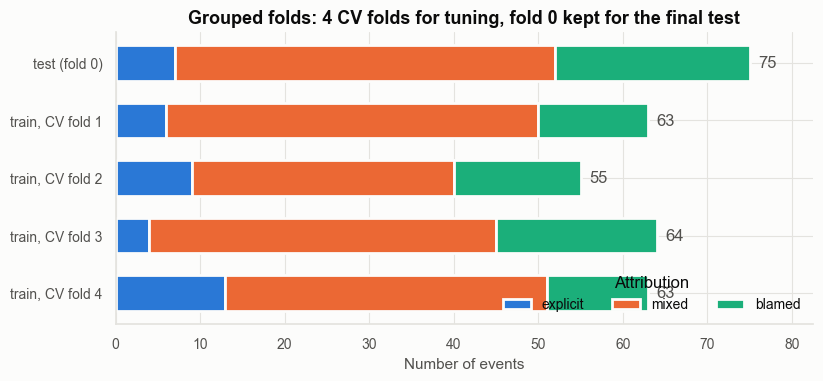

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
plot_tbl = split_tbl[CLASSES].iloc[::-1]
left = np.zeros(len(plot_tbl))
for cls in CLASSES:
    ax.barh(plot_tbl.index, plot_tbl[cls], left=left, color=CLASS_COLORS[cls], edgecolor=SURFACE,
            linewidth=2, height=0.62, label=cls)
    left += plot_tbl[cls].to_numpy()
for i, total in enumerate(left):
    ax.text(total + 1, i, f"{int(total)}", va="center", color=TEXT2)
ax.set_xlabel("Number of events")
ax.set_title("Grouped folds: 4 CV folds for tuning, fold 0 kept for the final test")
ax.legend(title="Attribution", loc="lower right", ncol=3)
ax.set_xlim(0, left.max() * 1.1)
savefig(fig, "fig19_split_composition")

**Observation.** Every fold contains all three classes, but the *explicit* count per fold is small (4–13). That is why fold-level scores will vary noticeably, and why we report the **spread** across folds, not only the mean.

## 5. Preprocessing pipeline
`make_preprocessor` rebuilds the Part 1 `ColumnTransformer` from `feature_spec.json`, with three options needed by specific models:

| Option | Why |
|---|---|
| `scaler="minmax"` | Multinomial Naive Bayes only accepts **non-negative** inputs; `StandardScaler` produces negatives, so NB uses `MinMaxScaler` instead. |
| `k` (χ² feature selection) | `SelectKBest(chi2, k)` after TF-IDF keeps the `k` n-grams most associated with the label. Because it sits **inside** the pipeline, it is re-fitted on each CV training part (no selection leakage). `k` is tuned like any hyperparameter. |
| `dense=True` | `HistGradientBoostingClassifier` does not accept sparse matrices. |
| `text_col` | Lets us swap in `text_clean_noverdict` for the sensitivity check. |

All imputers, scalers, encoders and the TF-IDF vocabulary are learned from the training part of each split only, because the whole preprocessor is a step of the model `Pipeline`.

In [6]:
TFIDF_PARAMS = spec["text_processing"]["tfidf"]          # ngram (1,2), english stop words, min_df 2, sublinear tf


def make_preprocessor(use_text=True, use_context=True, scaler="standard", k=None, dense=False,
                      text_col="text_clean"):
    # ColumnTransformer for the text-only, context-only or combined configuration (Part 1, Section 6.7)
    scaler_cls = StandardScaler if scaler == "standard" else MinMaxScaler

    def numeric_pipe():
        return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", scaler_cls())])

    blocks = []
    if use_text:
        tfidf = TfidfVectorizer(ngram_range=tuple(TFIDF_PARAMS["ngram_range"]), stop_words=TFIDF_PARAMS["stop_words"],
                                min_df=TFIDF_PARAMS["min_df"], sublinear_tf=TFIDF_PARAMS["sublinear_tf"])
        text_block = Pipeline([("vec", tfidf), ("select", SelectKBest(chi2, k=k if k else "all"))])
        blocks += [("tfidf", text_block, text_col),
                   ("text_num", numeric_pipe(), BLOCKS["text_numeric"]),
                   ("text_bin", "passthrough", BLOCKS["text_binary"])]
    if use_context:
        blocks += [("ctx_cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=3,
                                             sparse_output=not dense), BLOCKS["context_categorical"]),
                   ("ctx_num", numeric_pipe(), BLOCKS["context_numeric"]),
                   ("ctx_bin", "passthrough", BLOCKS["context_binary"])]
    if not blocks:
        raise ValueError("use_text and use_context cannot both be False")
    return ColumnTransformer(blocks, remainder="drop", sparse_threshold=0 if dense else 0.3,
                             verbose_feature_names_out=True)


CONFIGS = {"Text only": (True, False), "Context only": (False, True), "Combined": (True, True)}
CONFIG_KEYS = {"Text only": "exp1_text_only", "Context only": "exp2_context_only", "Combined": "exp3_combined"}

rows = []
for cfg, (t, c) in CONFIGS.items():
    Xtr = make_preprocessor(t, c).fit_transform(train_df, y_train)
    rows.append({"configuration": cfg, "input columns": len(EXPERIMENTS[CONFIG_KEYS[cfg]]["columns"]),
                 "features after preprocessing (fitted on all 245 train events)": Xtr.shape[1]})
display(pd.DataFrame(rows).set_index("configuration"))

,input columns,features after preprocessing (fitted on all 245 train events)
configuration,,
Text only,10,2107
Context only,26,62
Combined,36,2169


**Observation.** The text configurations have far more features (thousands of TF-IDF uni/bi-grams) than training events (245). This "p ≫ n" situation is why we prefer **regularised** linear models, Naive Bayes, and tree ensembles with feature sub-sampling, and why χ² selection is worth tuning.

## 6. Model selection
The proposal fixed two groups of models. We add Random Forest as a second, bagging-based ensemble so RQ3 compares *two* ensemble families, not one.

| Group | Model | Why it suits this problem | Class-imbalance handling |
|---|---|---|---|
| Reference | **Majority class** (`DummyClassifier`) | Lower bound: always predicts *mixed*. Any useful model must beat macro-F1 = 0.25. | – |
| Traditional (baseline) | **Multinomial Naive Bayes** | Classic, fast text classifier; strong on small data because it has very few parameters. | `fit_prior` tuned (False = uniform class prior) |
| Traditional (baseline) | **Logistic Regression** | Regularised linear model; coefficients are directly interpretable per class (RQ1). | `class_weight="balanced"` |
| Traditional (comparative) | **Linear SVC** | Max-margin linear model; often the best linear text classifier on sparse TF-IDF. | `class_weight="balanced"` |
| Ensemble (bagging) | **Random Forest** | Averages many decorrelated trees; handles mixed text + tabular features and non-linear interactions; robust to noisy features. | `class_weight="balanced_subsample"` |
| Ensemble (boosting) | **Histogram Gradient Boosting** | scikit-learn's LightGBM-style boosting (the "gradient-boosting classifier" from the proposal; XGBoost was optional and is not needed). | `class_weight="balanced"` |

**Metric.** Macro-F1 is the primary metric (it averages F1 over the three classes, so the 39 *explicit* events weigh as much as the 199 *mixed*). We also report accuracy, balanced accuracy (= macro recall), macro precision/recall, per-class F1 and the confusion matrix.

In [7]:
# Hyperparameter grids. `pre__tfidf__select__k` tunes the chi2 feature selection (text configs only).
MODEL_SPECS = {
    "Majority": dict(group="Reference", scaler="standard", dense=False,
                     make=lambda: DummyClassifier(strategy="most_frequent"), grid={}, k_grid=None),
    "Naive Bayes": dict(group="Traditional", scaler="minmax", dense=False,
                        make=lambda: MultinomialNB(),
                        grid={"clf__alpha": [0.05, 0.1, 0.3, 1.0], "clf__fit_prior": [True, False]},
                        k_grid=[300, 1000, "all"]),
    "Logistic Regression": dict(group="Traditional", scaler="standard", dense=False,
                                make=lambda: LogisticRegression(class_weight="balanced", max_iter=5000),
                                grid={"clf__C": [0.1, 0.3, 1, 3, 10, 30]}, k_grid=[1000, "all"]),
    "Linear SVC": dict(group="Traditional", scaler="standard", dense=False,
                       make=lambda: LinearSVC(class_weight="balanced", max_iter=20000),
                       grid={"clf__C": [0.01, 0.03, 0.1, 0.3, 1]}, k_grid=[300, 1000, "all"]),
    "Random Forest": dict(group="Ensemble", scaler="standard", dense=False,
                          make=lambda: RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample",
                                                              random_state=RANDOM_STATE, n_jobs=-1),
                          grid={"clf__max_depth": [None, 10], "clf__min_samples_leaf": [1, 3],
                                "clf__max_features": ["sqrt", 0.05]},
                          k_grid=[1000, "all"]),
    "Gradient Boosting": dict(group="Ensemble", scaler="standard", dense=True,
                              make=lambda: HistGradientBoostingClassifier(class_weight="balanced", max_depth=3,
                                                                          min_samples_leaf=10, early_stopping=False,
                                                                          random_state=RANDOM_STATE),
                              grid={"clf__learning_rate": [0.05, 0.1], "clf__max_iter": [100, 200]},
                              k_grid=[100, 300]),       # dense matrices: keep the text block small
}
MODELS = list(MODEL_SPECS)
print("Models:", MODELS)
print("Grid sizes per configuration:",
      {m: int(np.prod([len(v) for v in s["grid"].values()] or [1])) for m, s in MODEL_SPECS.items()})

Models: ['Majority', 'Naive Bayes', 'Logistic Regression', 'Linear SVC', 'Random Forest', 'Gradient Boosting']
Grid sizes per configuration: {'Majority': 1, 'Naive Bayes': 8, 'Logistic Regression': 6, 'Linear SVC': 5, 'Random Forest': 8, 'Gradient Boosting': 4}


## 7. Model training and hyperparameter tuning
For each of the 6 models × 3 configurations we run `GridSearchCV` over the grouped 4-fold CV, scoring **macro-F1**. The best setting is refitted on all 245 training events (`refit=True`). We keep, for every combination, the best mean CV score, its standard deviation across folds, the four individual fold scores (for paired comparisons later) and the tuning time.

*Note:* the gradient-boosting search runs single-process (`n_jobs=1`) because the model is itself multi-threaded; running both in parallel oversubscribes the CPU and is many times slower.

In [8]:
def build_pipeline(model, cfg, **pre_overrides):
    # Full pipeline = preprocessor + classifier for one model/configuration
    s = MODEL_SPECS[model]
    t, c = CONFIGS[cfg]
    pre_kwargs = dict(use_text=t, use_context=c, scaler=s["scaler"], dense=s["dense"])
    pre_kwargs.update(pre_overrides)
    return Pipeline([("pre", make_preprocessor(**pre_kwargs)), ("clf", s["make"]())])


def param_grid(model, cfg):
    s = MODEL_SPECS[model]
    grid = dict(s["grid"])
    if CONFIGS[cfg][0] and s["k_grid"]:
        grid["pre__tfidf__select__k"] = s["k_grid"]
    return grid


searches, cv_rows = {}, []
for cfg in CONFIGS:
    for model in MODELS:
        t0 = time.time()
        gs = GridSearchCV(build_pipeline(model, cfg), param_grid(model, cfg), cv=CV, scoring="f1_macro",
                          n_jobs=1 if model == "Gradient Boosting" else -1, refit=True)
        gs.fit(train_df, y_train)
        best = gs.best_index_
        folds = [gs.cv_results_[f"split{i}_test_score"][best] for i in range(4)]
        searches[(model, cfg)] = gs
        cv_rows.append({"model": model, "group": MODEL_SPECS[model]["group"], "config": cfg,
                        "cv_macro_f1": gs.best_score_, "cv_std": np.std(folds),
                        **{f"fold{i + 1}": f for i, f in enumerate(folds)},
                        "best_params": {k.replace("clf__", "").replace("pre__tfidf__select__", "chi2_"): v
                                        for k, v in gs.best_params_.items()},
                        "n_settings": len(gs.cv_results_["params"]), "seconds": round(time.time() - t0, 1)})
        print(f"{cfg:13s} | {model:20s} CV macro-F1 = {gs.best_score_:.3f} ± {np.std(folds):.3f}  "
              f"({len(gs.cv_results_['params'])} settings, {time.time() - t0:.0f}s)")

cv_results = pd.DataFrame(cv_rows)
cv_results.drop(columns=["best_params"]).to_csv(RESULTS_DIR / "cv_results.csv", index=False)

Text only     | Majority             CV macro-F1 = 0.256 ± 0.012  (1 settings, 4s)


Text only     | Naive Bayes          CV macro-F1 = 0.553 ± 0.028  (24 settings, 4s)


Text only     | Logistic Regression  CV macro-F1 = 0.536 ± 0.048  (12 settings, 1s)


Text only     | Linear SVC           CV macro-F1 = 0.514 ± 0.068  (15 settings, 1s)


Text only     | Random Forest        CV macro-F1 = 0.618 ± 0.052  (16 settings, 34s)


Text only     | Gradient Boosting    CV macro-F1 = 0.497 ± 0.052  (8 settings, 313s)


... (6 outputs left out)

Combined      | Logistic Regression  CV macro-F1 = 0.554 ± 0.062  (12 settings, 1s)


Combined      | Linear SVC           CV macro-F1 = 0.561 ± 0.056  (15 settings, 1s)


Combined      | Random Forest        CV macro-F1 = 0.665 ± 0.039  (16 settings, 21s)


Combined      | Gradient Boosting    CV macro-F1 = 0.528 ± 0.062  (8 settings, 22s)


In [9]:
show = cv_results[["config", "model", "group", "cv_macro_f1", "cv_std", "best_params", "seconds"]].copy()
show = show.sort_values(["config", "cv_macro_f1"], ascending=[True, False])
display(show.style.format({"cv_macro_f1": "{:.3f}", "cv_std": "{:.3f}"}).hide(axis="index"))

config,model,group,cv_macro_f1,cv_std,best_params,seconds
Combined,Random Forest,Ensemble,0.665,0.039,"{'max_depth': 10, 'max_features': 0.05, 'min_samples_leaf': 3, 'chi2_k': 1000}",21.100000
Combined,Naive Bayes,Traditional,0.592,0.039,"{'alpha': 0.05, 'fit_prior': False, 'chi2_k': 1000}",2.000000
Combined,Linear SVC,Traditional,0.561,0.056,"{'C': 1, 'chi2_k': 300}",1.100000
Combined,Logistic Regression,Traditional,0.554,0.062,"{'C': 10, 'chi2_k': 'all'}",1.300000
Combined,Gradient Boosting,Ensemble,0.528,0.062,"{'learning_rate': 0.05, 'max_iter': 100, 'chi2_k': 300}",21.500000
Combined,Majority,Reference,0.256,0.012,{},0.200000
Context only,Random Forest,Ensemble,0.510,0.083,"{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 3}",9.900000
Context only,Linear SVC,Traditional,0.497,0.051,{'C': 0.1},0.100000
Context only,Logistic Regression,Traditional,0.494,0.060,{'C': 0.1},0.300000
Context only,Naive Bayes,Traditional,0.468,0.049,"{'alpha': 0.3, 'fit_prior': False}",4.300000


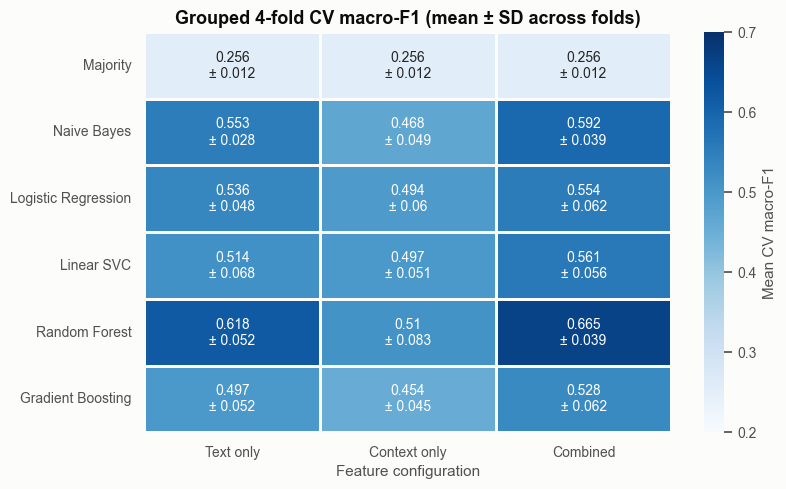

In [10]:
heat = cv_results.pivot(index="model", columns="config", values="cv_macro_f1").reindex(index=MODELS, columns=CONFIGS)
spread = cv_results.pivot(index="model", columns="config", values="cv_std").reindex(index=MODELS, columns=CONFIGS)
annot = heat.round(3).astype(str) + "\n± " + spread.round(3).astype(str)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
sns.heatmap(heat, annot=annot, fmt="", cmap=SEQ_CMAP, vmin=0.2, vmax=0.7, linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "Mean CV macro-F1"}, ax=ax, annot_kws={"fontsize": 10})
ax.set_title("Grouped 4-fold CV macro-F1 (mean ± SD across folds)")
ax.set_xlabel("Feature configuration")
ax.set_ylabel("")
savefig(fig, "fig20_cv_macro_f1_heatmap")

**What we see.**
- Every trained model beats the majority reference (≈ 0.26) by a wide margin, so the text and context carry real signal about how the AI link was established.
- **Random Forest on the combined features** has the highest mean CV macro-F1 (0.665), followed by the text-only Random Forest (0.618) and the combined Naive Bayes (0.592).
- For **all five** trained models, the combined configuration scores higher in CV than text only (Section 11 tests whether this gain is reliable).
- **Context alone** is clearly weaker than any configuration that contains text: who/where/when an event happened says much less about the attribution than *how it was reported*.
- The fold-to-fold SD (≈ 0.03–0.08) is of the same order as many of the gaps between models. Differences of one or two points should not be over-interpreted; Section 11 compares models fold by fold.

## 8. Model optimisation and performance improvement
Beyond the grid search we test four ideas, all judged by **CV on the training set only** (the test fold stays untouched):
1. **Class weighting:** does re-weighting the minority classes help, as the proposal expected?
2. **χ² feature selection:** how many TF-IDF n-grams should be kept?
3. **Soft-voting ensemble:** does averaging the probabilities of the best models beat the single best model?
4. **Stability:** does Random Forest's result depend on its random seed? How does performance grow with more data (learning curve)?

### 8.1 Class weighting
Each linear/ensemble model is re-run on the combined configuration with its tuned hyperparameters, once **with** and once **without** class weighting. Besides macro-F1 we look at the CV recall of the smallest class, *explicit*.

In [11]:
def cv_predictions(estimator, X=train_df, y=y_train):
    # Out-of-fold predictions over the grouped 4-fold CV
    return cross_val_predict(estimator, X, y, cv=CV, n_jobs=-1)


def fold_mean_f1(estimator, X=train_df, y=y_train):
    return cross_val_score(estimator, X, y, cv=CV, scoring="f1_macro", n_jobs=-1).mean()


weight_rows = []
for model in ["Logistic Regression", "Linear SVC", "Random Forest", "Gradient Boosting"]:
    tuned = searches[(model, "Combined")].best_estimator_
    for weighted in (True, False):
        est = clone(tuned)
        if not weighted:
            est.set_params(clf__class_weight=None)
        oof = cv_predictions(est)
        weight_rows.append({"model": model, "class weighting": "balanced" if weighted else "none",
                            "CV macro-F1": fold_mean_f1(est),
                            "explicit recall": recall_score(y_train, oof, labels=["explicit"], average="macro"),
                            "blamed recall": recall_score(y_train, oof, labels=["blamed"], average="macro")})
weight_tbl = pd.DataFrame(weight_rows)
display(weight_tbl.style.format(precision=3).hide(axis="index"))

model,class weighting,CV macro-F1,explicit recall,blamed recall
Logistic Regression,balanced,0.554,0.375,0.610
Logistic Regression,none,0.542,0.312,0.593
Linear SVC,balanced,0.561,0.375,0.576
Linear SVC,none,0.536,0.281,0.542
Random Forest,balanced,0.665,0.562,0.661
Random Forest,none,0.306,0.000,0.085
Gradient Boosting,balanced,0.528,0.281,0.576
Gradient Boosting,none,0.470,0.094,0.441


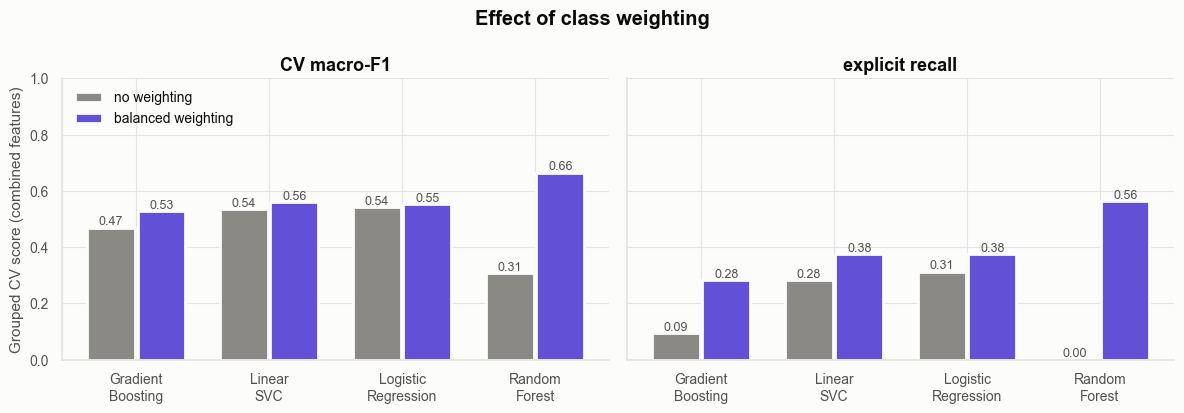

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, metric in zip(axes, ["CV macro-F1", "explicit recall"]):
    p = weight_tbl.pivot(index="model", columns="class weighting", values=metric)[["none", "balanced"]]
    x = np.arange(len(p))
    ax.bar(x - 0.19, p["none"], width=0.36, color=NEUTRAL, edgecolor=SURFACE, linewidth=2, label="no weighting")
    ax.bar(x + 0.19, p["balanced"], width=0.36, color=ACCENT, edgecolor=SURFACE, linewidth=2, label="balanced weighting")
    for xi, (a, b) in enumerate(zip(p["none"], p["balanced"])):
        ax.text(xi - 0.19, a + 0.01, f"{a:.2f}", ha="center", fontsize=9, color=TEXT2)
        ax.text(xi + 0.19, b + 0.01, f"{b:.2f}", ha="center", fontsize=9, color=TEXT2)
    ax.set_xticks(x, [m.replace(" ", "\n") for m in p.index])
    ax.set_title(metric)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Grouped CV score (combined features)")
axes[0].legend(loc="upper left")
fig.suptitle("Effect of class weighting", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig21_class_weighting")

**What we see.** Class weighting helps every model, and for Random Forest it is essential: without it the forest predicts almost only *mixed* (explicit recall 0, macro-F1 ≈ 0.31, barely above the majority reference). With balanced weights its explicit recall rises to ≈ 0.56 and macro-F1 to 0.665. For the linear models and boosting the effect is smaller but in the same direction. We therefore keep class weighting in all final models, as the proposal planned.

### 8.2 How many n-grams to keep (χ² feature selection)
The best Random Forest and Logistic Regression (combined features) are re-scored with different numbers of TF-IDF n-grams kept by `SelectKBest(chi2)`. Selection is re-fitted inside every CV training part.

In [13]:
K_VALUES = [50, 100, 300, 600, 1000, 2000, "all"]
k_rows = []
for model in ["Random Forest", "Logistic Regression", "Naive Bayes"]:
    tuned = searches[(model, "Combined")].best_estimator_
    for k in K_VALUES:
        est = clone(tuned).set_params(pre__tfidf__select__k=k)
        scores = cross_val_score(est, train_df, y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
        k_rows.append({"model": model, "k": k, "cv_macro_f1": scores.mean(), "cv_std": scores.std()})
k_tbl = pd.DataFrame(k_rows)
n_vocab = searches[("Random Forest", "Combined")].best_estimator_.named_steps["pre"] \
    .named_transformers_["tfidf"].named_steps["vec"].vocabulary_.__len__()
print(f"TF-IDF vocabulary on the full training set: {n_vocab} n-grams ('all' = {n_vocab})")
display(k_tbl.pivot(index="k", columns="model", values="cv_macro_f1").reindex(K_VALUES).round(3))

TF-IDF vocabulary on the full training set: 2098 n-grams ('all' = 2098)


model,Logistic Regression,Naive Bayes,Random Forest
k,,,
50,0.493,0.507,0.605
100,0.501,0.510,0.633
300,0.532,0.549,0.632
600,0.528,0.574,0.654
1000,0.533,0.592,0.665
2000,0.554,0.588,0.605
all,0.554,0.588,0.605


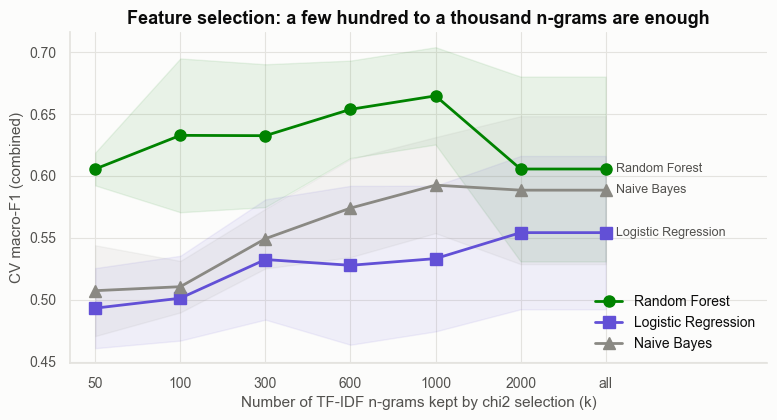

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.3))
model_marks = {"Random Forest": ("#008300", "o"), "Logistic Regression": (ACCENT, "s"), "Naive Bayes": (NEUTRAL, "^")}
xpos = np.arange(len(K_VALUES))
for model, (col, mk) in model_marks.items():
    sub = k_tbl[k_tbl.model == model].set_index("k").reindex(K_VALUES)
    ax.plot(xpos, sub["cv_macro_f1"], color=col, marker=mk, markersize=8, linewidth=2, label=model)
    ax.fill_between(xpos, sub["cv_macro_f1"] - sub["cv_std"], sub["cv_macro_f1"] + sub["cv_std"], color=col, alpha=0.08)
    ax.text(xpos[-1] + 0.12, sub["cv_macro_f1"].iloc[-1], model, va="center", color=TEXT2, fontsize=9)
ax.set_xticks(xpos, [str(k) for k in K_VALUES])
ax.set_xlim(-0.3, len(K_VALUES) + 0.9)
ax.set_xlabel("Number of TF-IDF n-grams kept by chi2 selection (k)")
ax.set_ylabel("CV macro-F1 (combined)")
ax.set_title("Feature selection: a few hundred to a thousand n-grams are enough")
ax.legend(loc="lower right")
savefig(fig, "fig22_chi2_k_curve")

**What we see.** Very aggressive selection (k = 50–100) hurts every model, because many weak attribution cues are thrown away. The models then differ: **Random Forest** peaks at k ≈ 1,000 and gets *worse* when all ~2,100 n-grams are kept (0.665 → 0.605), because with feature sub-sampling each tree then sees mostly rare, uninformative n-grams. **Naive Bayes** also prefers ~1,000, while **Logistic Regression** is best with all n-grams (its L2 penalty already shrinks the useless ones). The tuned `k` values from Section 7 agree with these curves, so tuning `k` inside the CV was worthwhile.

### 8.3 Soft-voting ensemble of the strongest models
Averaging predicted probabilities of different model families can reduce variance. We combine the tuned combined-feature Random Forest, Naive Bayes and Logistic Regression (Linear SVC has no `predict_proba`, and gradient boosting was weaker).

In [15]:
best_combined = {m: searches[(m, "Combined")].best_estimator_ for m in ["Random Forest", "Naive Bayes", "Logistic Regression"]}
voting_variants = {
    "Vote: RF + NB": VotingClassifier([("rf", clone(best_combined["Random Forest"])),
                                       ("nb", clone(best_combined["Naive Bayes"]))], voting="soft"),
    "Vote: RF + NB + LR": VotingClassifier([(k, clone(v)) for k, v in zip(["rf", "nb", "lr"], best_combined.values())],
                                           voting="soft"),
}
vote_rows = [{"model": "Random Forest (single, tuned)", "cv_macro_f1": searches[("Random Forest", "Combined")].best_score_}]
for name, est in voting_variants.items():
    s = cross_val_score(est, train_df, y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
    vote_rows.append({"model": name, "cv_macro_f1": s.mean(), "cv_std": s.std()})
vote_tbl = pd.DataFrame(vote_rows)
display(vote_tbl.style.format(precision=3, na_rep="").hide(axis="index"))

model,cv_macro_f1,cv_std
"Random Forest (single, tuned)",0.665,
Vote: RF + NB,0.590,0.028
Vote: RF + NB + LR,0.597,0.050


**What we see.** The voting ensembles do **not** beat the single tuned Random Forest: Naive Bayes and Logistic Regression make many of the same mistakes as each other and are individually weaker, so averaging pulls the forest's probabilities towards them. Ensembling adds complexity without a gain, so we do not use it.

### 8.4 Stability: random seeds and the learning curve
A Random Forest's result can depend on its random seed. We re-run the tuned combined-feature forest with five seeds. The learning curve then shows how CV macro-F1 changes as the number of training events grows.

In [16]:
rf_tuned = searches[("Random Forest", "Combined")].best_estimator_
seed_rows = []
for seed in [0, 1, 2, 3, RANDOM_STATE]:
    s = cross_val_score(clone(rf_tuned).set_params(clf__random_state=seed), train_df, y_train, cv=CV,
                        scoring="f1_macro", n_jobs=-1)
    seed_rows.append({"seed": seed, "cv_macro_f1": s.mean(), "cv_std": s.std()})
seed_tbl = pd.DataFrame(seed_rows)
display(seed_tbl.round(3).T)
print(f"Across seeds: mean {seed_tbl.cv_macro_f1.mean():.3f}, range "
      f"{seed_tbl.cv_macro_f1.min():.3f}-{seed_tbl.cv_macro_f1.max():.3f}")

,0,1,2,3,4
seed,0.000,1.000,2.000,3.00,42.000
cv_macro_f1,0.635,0.665,0.659,0.66,0.665
cv_std,0.047,0.039,0.048,0.03,0.039


Across seeds: mean 0.657, range 0.635-0.665


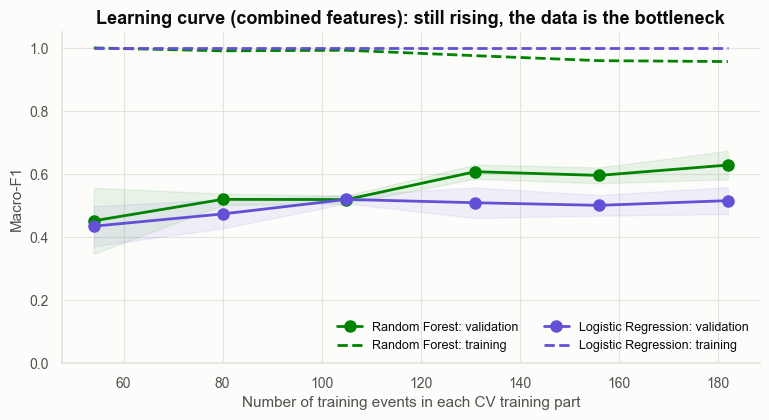

In [17]:
lc_models = {"Random Forest": (searches[("Random Forest", "Combined")].best_estimator_, "#008300"),
             "Logistic Regression": (searches[("Logistic Regression", "Combined")].best_estimator_, ACCENT)}
fig, ax = plt.subplots(figsize=(9, 4.3))
for name, (est, col) in lc_models.items():
    sizes, tr_sc, va_sc = learning_curve(clone(est), train_df, y_train, cv=CV, scoring="f1_macro",
                                         train_sizes=np.linspace(0.3, 1.0, 6), shuffle=True,
                                         random_state=RANDOM_STATE, n_jobs=-1)
    ax.plot(sizes, va_sc.mean(axis=1), color=col, marker="o", markersize=8, linewidth=2, label=f"{name}: validation")
    ax.plot(sizes, tr_sc.mean(axis=1), color=col, linestyle="--", linewidth=2, label=f"{name}: training")
    ax.fill_between(sizes, va_sc.mean(axis=1) - va_sc.std(axis=1), va_sc.mean(axis=1) + va_sc.std(axis=1),
                    color=col, alpha=0.08)
ax.set_xlabel("Number of training events in each CV training part")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1.05)
ax.set_title("Learning curve (combined features): still rising, the data is the bottleneck")
ax.legend(loc="lower right", ncol=2, fontsize=9)
savefig(fig, "fig23_learning_curve")

**What we see.**
- The forest's CV score moves by a couple of points between seeds, which is smaller than the gap to most other models but a reminder that ±0.02 differences are noise.
- Training scores are near 1 while validation scores are around 0.5–0.65: the models are **variance-limited** (they could fit the training data perfectly but generalise much less well).
- The Random Forest's validation score is still rising at the full training size (≈ 0.45 at 55 events → ≈ 0.63 at 180), while Logistic Regression has flattened at ≈ 0.52. **More labelled events** are therefore the most promising way to improve the forest, and they would likely widen its lead.

## 9. Final model selection
**Rule (decided before looking at the test set):** choose the model/configuration with the highest mean grouped-CV macro-F1. The test set plays no part in this choice.

In [18]:
ranked = cv_results[cv_results.model != "Majority"].sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
display(ranked[["model", "config", "cv_macro_f1", "cv_std", "best_params"]].head(6)
        .style.format({"cv_macro_f1": "{:.3f}", "cv_std": "{:.3f}"}).hide(axis="index"))

FINAL_MODEL, FINAL_CONFIG = ranked.loc[0, "model"], ranked.loc[0, "config"]
final_search = searches[(FINAL_MODEL, FINAL_CONFIG)]
final_estimator = final_search.best_estimator_
print(f"Selected: {FINAL_MODEL} on '{FINAL_CONFIG}' features, CV macro-F1 = {final_search.best_score_:.3f}")
print("Hyperparameters:", final_search.best_params_)

model,config,cv_macro_f1,cv_std,best_params
Random Forest,Combined,0.665,0.039,"{'max_depth': 10, 'max_features': 0.05, 'min_samples_leaf': 3, 'chi2_k': 1000}"
Random Forest,Text only,0.618,0.052,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'chi2_k': 1000}"
Naive Bayes,Combined,0.592,0.039,"{'alpha': 0.05, 'fit_prior': False, 'chi2_k': 1000}"
Linear SVC,Combined,0.561,0.056,"{'C': 1, 'chi2_k': 300}"
Logistic Regression,Combined,0.554,0.062,"{'C': 10, 'chi2_k': 'all'}"
Naive Bayes,Text only,0.553,0.028,"{'alpha': 0.1, 'fit_prior': False, 'chi2_k': 1000}"


Selected: Random Forest on 'Combined' features, CV macro-F1 = 0.665
Hyperparameters: {'clf__max_depth': 10, 'clf__max_features': 0.05, 'clf__min_samples_leaf': 3, 'pre__tfidf__select__k': 1000}


**Why this model.** It has the best cross-validated macro-F1, it uses both kinds of information (supporting RQ2), its result is stable across random seeds (8.4), and it produces class probabilities for the demo. Its hyperparameters (limited depth, `min_samples_leaf`, feature sub-sampling, χ² selection) all restrict complexity, which matters with 245 training events.

## 10. Evaluation on the held-out test set
Now, and only now, the 75 test events (companies never seen in training) are scored. We evaluate **every** tuned model so they can be compared, but the final choice above is already fixed.

With 75 events (7 explicit) one prediction can move per-class scores a lot, so for the final model we add a **95 % bootstrap confidence interval** (2,000 resamples of the test events).

In [19]:
def scores(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=CLASSES, zero_division=0)
    return {"macro_f1": f1_score(y_true, y_pred, average="macro", labels=CLASSES, zero_division=0),
            "accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_precision": precision_score(y_true, y_pred, average="macro", labels=CLASSES, zero_division=0),
            "macro_recall": recall_score(y_true, y_pred, average="macro", labels=CLASSES, zero_division=0),
            **{f"f1_{c}": f[i] for i, c in enumerate(CLASSES)}}


test_rows, test_preds = [], {}
for (model, cfg), gs in searches.items():
    pred = gs.predict(test_df)
    test_preds[(model, cfg)] = pred
    test_rows.append({"model": model, "group": MODEL_SPECS[model]["group"], "config": cfg,
                      "cv_macro_f1": gs.best_score_, **scores(y_test, pred)})
test_results = pd.DataFrame(test_rows)
test_results.to_csv(RESULTS_DIR / "test_results_all_models.csv", index=False)

metric_cols = ["cv_macro_f1", "macro_f1", "accuracy", "balanced_accuracy", "macro_precision", "macro_recall",
               "f1_explicit", "f1_mixed", "f1_blamed"]
display(test_results.sort_values(["config", "cv_macro_f1"], ascending=[True, False])
        [["config", "model"] + metric_cols].style.format(precision=3).hide(axis="index")
        .background_gradient(subset=["macro_f1"], cmap=SEQ_CMAP, vmin=0.2, vmax=0.75))

config,model,cv_macro_f1,macro_f1,accuracy,balanced_accuracy,macro_precision,macro_recall,f1_explicit,f1_mixed,f1_blamed
Combined,Random Forest,0.665,0.570,0.653,0.597,0.559,0.597,0.333,0.723,0.653
Combined,Naive Bayes,0.592,0.585,0.693,0.586,0.597,0.586,0.333,0.767,0.654
Combined,Linear SVC,0.561,0.552,0.653,0.557,0.554,0.557,0.308,0.721,0.627
Combined,Logistic Regression,0.554,0.533,0.627,0.542,0.538,0.542,0.308,0.699,0.593
Combined,Gradient Boosting,0.528,0.547,0.653,0.564,0.542,0.564,0.267,0.732,0.642
Combined,Majority,0.256,0.250,0.600,0.333,0.200,0.333,0.000,0.750,0.000
Context only,Random Forest,0.510,0.463,0.533,0.469,0.474,0.469,0.308,0.617,0.464
Context only,Linear SVC,0.497,0.417,0.480,0.432,0.420,0.432,0.267,0.557,0.429
Context only,Logistic Regression,0.494,0.354,0.400,0.395,0.368,0.395,0.200,0.429,0.433
Context only,Naive Bayes,0.468,0.506,0.520,0.556,0.507,0.556,0.471,0.548,0.500


In [20]:
def bootstrap_ci(y_true, y_pred, metric, n_boot=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals = [metric(y_true[idx], y_pred[idx]) for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(vals, [2.5, 97.5])


macro = lambda a, b: f1_score(a, b, average="macro", labels=CLASSES, zero_division=0)
final_pred = test_preds[(FINAL_MODEL, FINAL_CONFIG)]
majority_pred = test_preds[("Majority", FINAL_CONFIG)]
final_scores = scores(y_test, final_pred)

ci_rows = []
for name, pred in [(f"{FINAL_MODEL} ({FINAL_CONFIG})", final_pred), ("Majority class", majority_pred)]:
    lo, hi = bootstrap_ci(y_test, pred, macro)
    bal_lo, bal_hi = bootstrap_ci(y_test, pred, balanced_accuracy_score)
    ci_rows.append({"model": name, "test macro-F1": macro(y_test, pred), "95% CI": f"[{lo:.3f}, {hi:.3f}]",
                    "balanced accuracy": balanced_accuracy_score(y_test, pred), "95% CI (bal. acc.)": f"[{bal_lo:.3f}, {bal_hi:.3f}]",
                    "accuracy": accuracy_score(y_test, pred)})
display(pd.DataFrame(ci_rows).style.format(precision=3).hide(axis="index"))
print(classification_report(y_test, final_pred, labels=CLASSES, digits=3, zero_division=0))

model,test macro-F1,95% CI,balanced accuracy,95% CI (bal. acc.),accuracy
Random Forest (Combined),0.570,"[0.439, 0.696]",0.597,"[0.442, 0.764]",0.653
Majority class,0.250,"[0.220, 0.276]",0.333,"[0.333, 0.333]",0.600


              precision    recall  f1-score   support

    explicit      0.273     0.429     0.333         7
       mixed      0.789     0.667     0.723        45
      blamed      0.615     0.696     0.653        23

    accuracy                          0.653        75
   macro avg      0.559     0.597     0.570        75
weighted avg      0.688     0.653     0.665        75



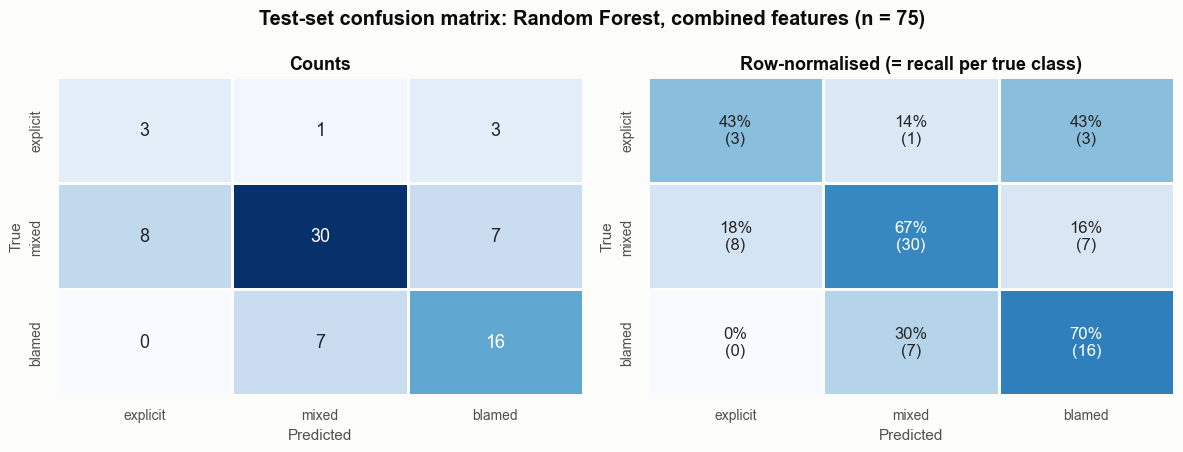

In [21]:
cm = confusion_matrix(y_test, final_pred, labels=CLASSES)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap=SEQ_CMAP, cbar=False, linewidths=2, linecolor=SURFACE,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0], annot_kws={"fontsize": 13})
axes[0].set_title("Counts")
annot = np.array([[f"{v:.0%}\n({c})" for v, c in zip(rv, rc)] for rv, rc in zip(cm_norm, cm)])
sns.heatmap(cm_norm, annot=annot, fmt="", cmap=SEQ_CMAP, vmin=0, vmax=1, cbar=False, linewidths=2,
            linecolor=SURFACE, xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], annot_kws={"fontsize": 12})
axes[1].set_title("Row-normalised (= recall per true class)")
for ax in axes:
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
fig.suptitle(f"Test-set confusion matrix: {FINAL_MODEL}, {FINAL_CONFIG.lower()} features (n = {len(y_test)})",
             fontweight="bold")
fig.tight_layout()
savefig(fig, "fig24_confusion_matrix_final")

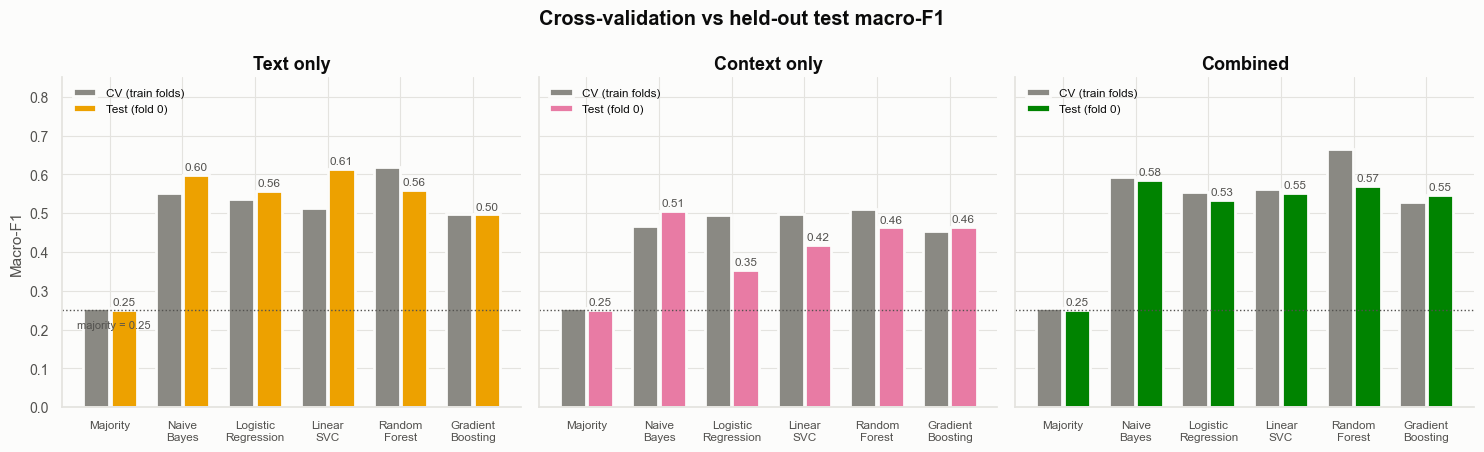

In [22]:
# CV vs test macro-F1 for the best setting of every model in every configuration
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, cfg in zip(axes, CONFIGS):
    sub = test_results[test_results.config == cfg].set_index("model").reindex(MODELS)
    x = np.arange(len(sub))
    ax.bar(x - 0.19, sub["cv_macro_f1"], width=0.36, color=NEUTRAL, edgecolor=SURFACE, linewidth=2, label="CV (train folds)")
    ax.bar(x + 0.19, sub["macro_f1"], width=0.36, color=CONFIG_COLORS[cfg], edgecolor=SURFACE, linewidth=2, label="Test (fold 0)")
    for xi, v in enumerate(sub["macro_f1"]):
        ax.text(xi + 0.19, v + 0.012, f"{v:.2f}", ha="center", fontsize=8.5, color=TEXT2)
    ax.axhline(0.25, color=TEXT2, linestyle=":", linewidth=1)
    ax.set_xticks(x, [m.replace(" ", "\n") for m in sub.index], fontsize=8.5)
    ax.set_title(cfg)
    ax.legend(loc="upper left", fontsize=8.5)
axes[0].set_ylabel("Macro-F1")
axes[0].text(-0.45, 0.225, "majority = 0.25", fontsize=8, color=TEXT2, ha="left", va="top")
axes[0].set_ylim(0, 0.85)
fig.suptitle("Cross-validation vs held-out test macro-F1", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig25_cv_vs_test")

**What we see.**
- The final model clearly beats the majority reference on the unseen companies, and its bootstrap interval lies well above 0.25. The interval is wide (roughly ± 0.1), the honest price of a 75-event test set.
- **mixed** is recognised best; **explicit** is the hardest class (7 test events, and its wording — CEO statements about AI — overlaps with *mixed* announcements that also mention AI).
- Test scores scatter around the CV scores by several points in both directions, and the test ranking differs from the CV ranking: for example the text-only Linear SVC scores 0.615 on the test set although it was only mid-table in CV (0.514), while the final forest scores 0.570 (CV 0.665). All of these test scores lie inside the final model's bootstrap interval, so the test set **cannot** separate them reliably. That is exactly why the final model was chosen on CV (which uses 245 events, not 75); picking whichever model happened to win on this particular test set would overstate its real performance.

## 11. Comparison of models and feature configurations (RQ2, RQ3)
### 11.1 RQ2: text only vs context only vs combined
For each model we compare the three configurations **fold by fold** (the same four CV folds), so the comparison is paired. We also report the paired test-set difference with a bootstrap CI.

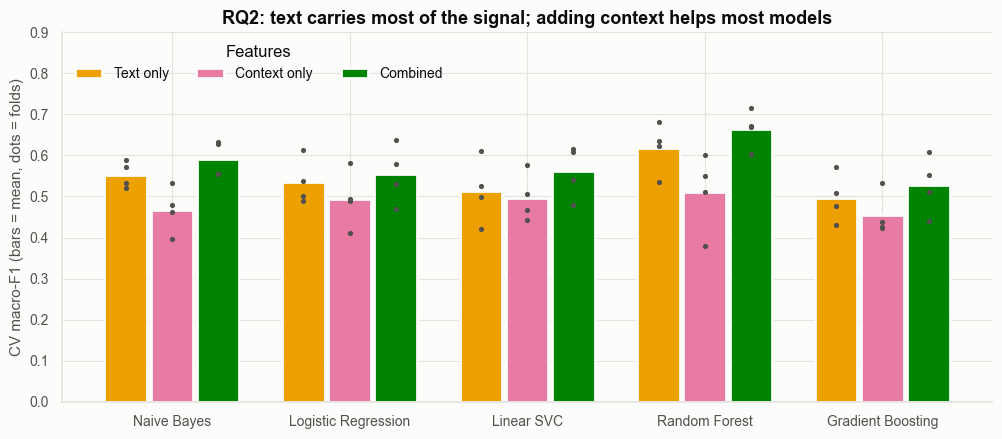

model,CV: text only,CV: context only,CV: combined,CV gain (combined - text),folds where combined wins,test gain,test gain 95% CI
Naive Bayes,0.553,0.468,0.592,0.039,3/4,-0.014,"[-0.079, +0.056]"
Logistic Regression,0.536,0.494,0.554,0.018,2/4,-0.024,"[-0.157, +0.094]"
Linear SVC,0.514,0.497,0.561,0.047,2/4,-0.063,"[-0.219, +0.094]"
Random Forest,0.618,0.510,0.665,0.046,3/4,0.010,"[-0.053, +0.079]"
Gradient Boosting,0.497,0.454,0.528,0.031,4/4,0.050,"[-0.096, +0.198]"


In [23]:
fold_cols = [f"fold{i}" for i in range(1, 5)]
fig, ax = plt.subplots(figsize=(12, 4.8))
trained = [m for m in MODELS if m != "Majority"]
width = 0.26
for j, cfg in enumerate(CONFIGS):
    sub = cv_results[cv_results.config == cfg].set_index("model").reindex(trained)
    x = np.arange(len(trained)) + (j - 1) * width
    ax.bar(x, sub["cv_macro_f1"], width=width - 0.02, color=CONFIG_COLORS[cfg], edgecolor=SURFACE,
           linewidth=2, label=cfg)
    for xi, (_, r) in zip(x, sub.iterrows()):          # individual fold scores as dots
        ax.scatter(np.full(4, xi), r[fold_cols].astype(float), s=14, color=TEXT2, zorder=3, linewidths=0)
ax.set_xticks(np.arange(len(trained)), trained)
ax.set_ylabel("CV macro-F1 (bars = mean, dots = folds)")
ax.set_ylim(0, 0.9)
ax.set_title("RQ2: text carries most of the signal; adding context helps most models")
ax.legend(title="Features", loc="upper left", ncol=3)
savefig(fig, "fig26_rq2_feature_configs")

rq2_rows = []
for m in trained:
    r = cv_results[cv_results.model == m].set_index("config")
    diff_folds = r.loc["Combined", fold_cols].astype(float).values - r.loc["Text only", fold_cols].astype(float).values
    pc, pt = test_preds[(m, "Combined")], test_preds[(m, "Text only")]
    lo, hi = bootstrap_ci(np.arange(len(y_test)), np.arange(len(y_test)),
                          lambda i, _: macro(y_test[i], pc[i]) - macro(y_test[i], pt[i]))
    rq2_rows.append({"model": m, "CV: text only": r.loc["Text only", "cv_macro_f1"],
                     "CV: context only": r.loc["Context only", "cv_macro_f1"],
                     "CV: combined": r.loc["Combined", "cv_macro_f1"],
                     "CV gain (combined - text)": diff_folds.mean(),
                     "folds where combined wins": f"{int((diff_folds > 0).sum())}/4",
                     "test gain": macro(y_test, pc) - macro(y_test, pt), "test gain 95% CI": f"[{lo:+.3f}, {hi:+.3f}]"})
rq2_tbl = pd.DataFrame(rq2_rows)
display(rq2_tbl.style.format(precision=3).hide(axis="index"))

**Answer to RQ2.** Text is the dominant source of information: text-only models are clearly better than context-only models (best CV 0.618 vs 0.510). Adding context to text raises the **CV** macro-F1 for **all five** models (+0.02 to +0.05, winning in 2–4 of the 4 folds), and the combined forest is the best model overall. However, on the 75-event test set the gain is inconsistent (between −0.06 and +0.05) and every bootstrap interval includes zero. Our conclusion: **combining text with metadata gives a modest improvement in cross-validation, but the evidence is not strong enough to call it a reliable improvement on new companies**; the wording of the claim is what really separates the classes.

### 11.2 RQ3: traditional vs ensemble classifiers

In [24]:
rq3 = (test_results[test_results.model != "Majority"]
       .assign(family=lambda d: d["group"])
       .groupby(["config", "family"])[["cv_macro_f1", "macro_f1", "balanced_accuracy", "f1_explicit"]]
       .max().round(3).rename(columns={"cv_macro_f1": "best CV macro-F1", "macro_f1": "best test macro-F1",
                                       "balanced_accuracy": "best test bal. acc.", "f1_explicit": "best test F1 explicit"}))
display(rq3)
best_per_model = (cv_results[cv_results.model != "Majority"].sort_values("cv_macro_f1", ascending=False)
                  .groupby("model").head(1)[["model", "group", "config", "cv_macro_f1", "cv_std", "seconds"]])
display(best_per_model.style.format({"cv_macro_f1": "{:.3f}", "cv_std": "{:.3f}"}).hide(axis="index"))

best CV macro-F1  best test macro-F1  best test bal. acc.  best test F1 explicit
config       family                                                                                       
Combined     Ensemble                0.665               0.570                0.597                  0.333
             Traditional             0.592               0.585                0.586                  0.333
Context only Ensemble                0.510               0.464                0.476                  0.308
             Traditional             0.497               0.506                0.556                  0.471
Text only    Ensemble                0.618               0.560                0.582                  0.353
             Traditional             0.553               0.615                0.608                  0.353

model,group,config,cv_macro_f1,cv_std,seconds
Random Forest,Ensemble,Combined,0.665,0.039,21.100000
Naive Bayes,Traditional,Combined,0.592,0.039,2.000000
Linear SVC,Traditional,Combined,0.561,0.056,1.100000
Logistic Regression,Traditional,Combined,0.554,0.062,1.300000
Gradient Boosting,Ensemble,Combined,0.528,0.062,21.500000


**Answer to RQ3.** The bagging ensemble (**Random Forest**) achieves the best cross-validated performance, most clearly with combined features where it can mix sparse text with tabular context. The boosting ensemble (**Histogram Gradient Boosting**), however, does **not** beat the traditional models: with only ~180 events per CV training part, boosting overfits quickly, and it needs a dense, reduced text representation. Among traditional models, **Naive Bayes** is very competitive for its simplicity and speed, and the linear models (Logistic Regression, Linear SVC) are close behind. So "ensemble" is not automatically better: averaging (bagging) helps on this small, noisy dataset, sequential boosting does not.

## 12. Robustness checks
The final configuration (same model, same hyperparameters) is re-trained under three changed conditions:

1. **Without register verdict phrases** (`text_clean_noverdict`): Part 1 found that 13 claims (12 of them *blamed*) contain the register's own wording such as "the memo does not mention AI". If the model depended on these phrases, it would be partly reading the label.
2. **Chronological hold-out:** train on events before 2026-07-15 (256), test on the 64 most recent ones. This mimics deploying the model on future events. 11 companies appear on both sides of this split, so we also report the score on recent events from *new* companies only.
3. **Probability calibration** (12.3): are the predicted probabilities shown in the demo trustworthy?

In [25]:
def refit_and_score(estimator, train, test):
    est = clone(estimator).fit(train, train[TARGET])
    pred = est.predict(test)
    return scores(test[TARGET].to_numpy(), pred), est


robust_rows = []
# (0) main result for reference
robust_rows.append({"setting": "Main: grouped test fold", "n_test": len(test_df), **final_scores})

# (1) no verdict phrases: swap the text column, same hyperparameters
nv_est = clone(final_estimator)
nv_pre = nv_est.named_steps["pre"]
nv_pre.transformers = [(n, t, "text_clean_noverdict" if n == "tfidf" else cols) for n, t, cols in nv_pre.transformers]
nv_cv = cross_val_score(nv_est, train_df, y_train, cv=CV, scoring="f1_macro", n_jobs=-1).mean()
nv_scores, _ = refit_and_score(nv_est, train_df, test_df)
robust_rows.append({"setting": "Text without verdict phrases", "n_test": len(test_df), **nv_scores})

# (2) chronological hold-out
chrono_train = df[df.chrono_split == "train"].reset_index(drop=True)
chrono_test = df[df.chrono_split == "test"].reset_index(drop=True)
ch_scores, ch_est = refit_and_score(final_estimator, chrono_train, chrono_test)
robust_rows.append({"setting": "Chronological: 64 most recent events", "n_test": len(chrono_test), **ch_scores})
new_co = ~chrono_test.company_group.isin(set(chrono_train.company_group))
ch_new_pred = ch_est.predict(chrono_test[new_co])
robust_rows.append({"setting": "Chronological: recent events, new companies only", "n_test": int(new_co.sum()),
                    **scores(chrono_test.loc[new_co, TARGET].to_numpy(), ch_new_pred)})
ch_major = scores(chrono_test[TARGET].to_numpy(), np.full(len(chrono_test), "mixed"))
robust_rows.append({"setting": "Chronological: majority reference", "n_test": len(chrono_test), **ch_major})

robust_tbl = pd.DataFrame(robust_rows)
print(f"Verdict-free text, CV macro-F1: {nv_cv:.3f} (main model: {final_search.best_score_:.3f})")
print("Chronological test classes:", chrono_test[TARGET].value_counts().reindex(CLASSES).to_dict())
display(robust_tbl[["setting", "n_test", "macro_f1", "balanced_accuracy", "accuracy", "f1_explicit", "f1_mixed", "f1_blamed"]]
        .style.format(precision=3).hide(axis="index"))
robust_tbl.to_csv(RESULTS_DIR / "robustness_checks.csv", index=False)

Verdict-free text, CV macro-F1: 0.654 (main model: 0.665)
Chronological test classes: {'explicit': 3, 'mixed': 40, 'blamed': 21}


setting,n_test,macro_f1,balanced_accuracy,accuracy,f1_explicit,f1_mixed,f1_blamed
Main: grouped test fold,75,0.570,0.597,0.653,0.333,0.723,0.653
Text without verdict phrases,75,0.567,0.579,0.680,0.267,0.753,0.680
Chronological: 64 most recent events,64,0.669,0.812,0.719,0.545,0.750,0.711
"Chronological: recent events, new companies only",53,0.679,0.814,0.736,0.571,0.781,0.686
Chronological: majority reference,64,0.256,0.333,0.625,0.000,0.769,0.000


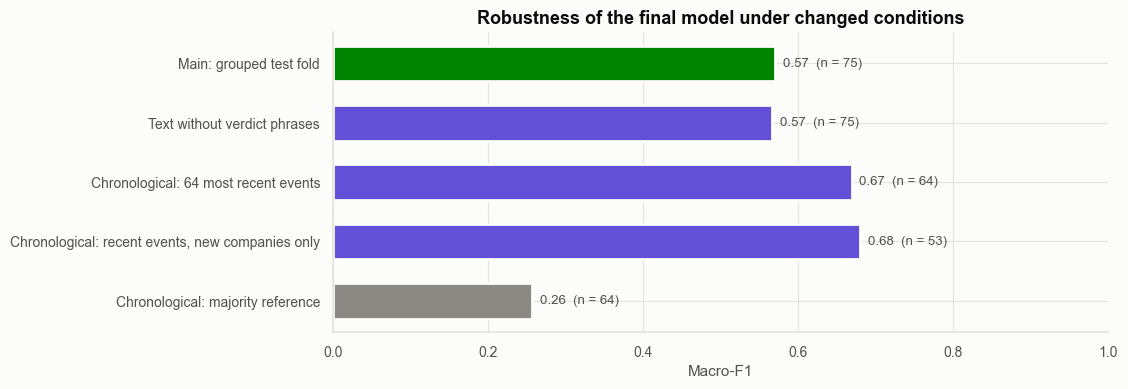

In [26]:
fig, ax = plt.subplots(figsize=(10, 3.9))
plot_r = robust_tbl.iloc[::-1]
colors = [NEUTRAL if "majority" in s else ("#008300" if s.startswith("Main") else ACCENT) for s in plot_r.setting]
ax.barh(plot_r.setting, plot_r.macro_f1, color=colors, edgecolor=SURFACE, linewidth=2, height=0.6)
for i, (v, n) in enumerate(zip(plot_r.macro_f1, plot_r.n_test)):
    ax.text(v + 0.01, i, f"{v:.2f}  (n = {n})", va="center", color=TEXT2, fontsize=9.5)
ax.set_xlim(0, 1)
ax.set_xlabel("Macro-F1")
ax.set_title("Robustness of the final model under changed conditions")
savefig(fig, "fig27_robustness")

**What we see.**
- **Verdict phrases:** removing them barely changes anything (CV 0.665 → 0.654, test 0.570 → 0.567), so the model is **not** relying on the register's own verdict wording; it learns from the general reporting language.
- **Chronological hold-out:** trained only on older events, the model scores macro-F1 ≈ 0.67 on the 64 most recent events, at least as well as on the grouped test fold, and the result holds when the 11 repeat companies are removed (≈ 0.68 on 53 events from new companies). So we see **no sign of performance decay over time** in this snapshot. This should not be over-read: the recent period contains only **3** *explicit* events, so the explicit F1 there rests on a handful of predictions, and the training set here is slightly larger (256 events). As the register grows, the model should still be **re-trained periodically** and re-checked on new events.

### 12.3 Probability calibration
The demo shows class probabilities, so we check whether they mean what they say. We compare the forest's raw probabilities with a **sigmoid-calibrated** version (`CalibratedClassifierCV`, 3 internal folds) using out-of-fold predictions from the grouped CV (training set only), scored by **log-loss** and **multi-class Brier score** (lower is better for both).

In [27]:
def brier_multi(y_true, proba, classes):
    onehot = (np.asarray(y_true)[:, None] == np.asarray(classes)[None, :]).astype(float)
    return np.mean(np.sum((proba - onehot) ** 2, axis=1))


calibrated = CalibratedClassifierCV(clone(final_estimator), method="sigmoid",
                                    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE))
cal_rows, oof_probas = [], {}
for name, est in [("Raw Random Forest probabilities", clone(final_estimator)), ("Sigmoid-calibrated", calibrated)]:
    proba = cross_val_predict(est, train_df, y_train, cv=CV, method="predict_proba", n_jobs=-1)
    classes_sorted = np.array(sorted(CLASSES))                    # predict_proba columns are alphabetical
    oof_probas[name] = (proba, classes_sorted)
    pred = classes_sorted[proba.argmax(axis=1)]
    cal_rows.append({"probabilities": name, "CV log-loss": log_loss(y_train, proba, labels=classes_sorted),
                     "CV Brier": brier_multi(y_train, proba, classes_sorted),
                     "CV macro-F1 of argmax": macro(y_train, pred)})
cal_tbl = pd.DataFrame(cal_rows)
display(cal_tbl.style.format(precision=3).hide(axis="index"))
USE_CALIBRATION = cal_tbl.loc[1, "CV log-loss"] < cal_tbl.loc[0, "CV log-loss"] and \
                  cal_tbl.loc[1, "CV macro-F1 of argmax"] >= cal_tbl.loc[0, "CV macro-F1 of argmax"] - 0.02
print("Use calibrated probabilities in the final pipeline:", USE_CALIBRATION)

probabilities,CV log-loss,CV Brier,CV macro-F1 of argmax
Raw Random Forest probabilities,0.788,0.455,0.665
Sigmoid-calibrated,0.703,0.408,0.505


Use calibrated probabilities in the final pipeline: False


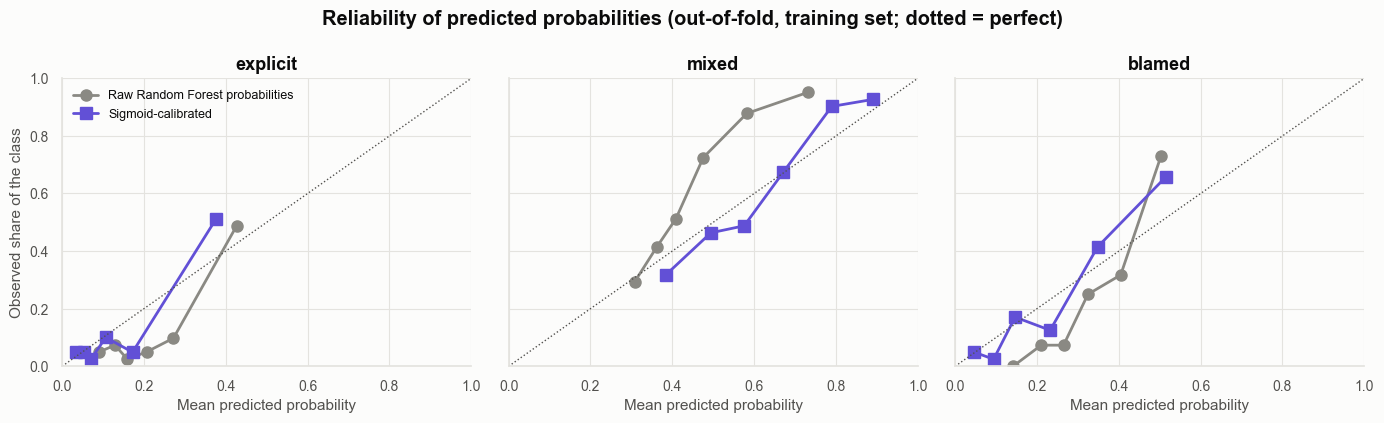

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
for ax, cls in zip(axes, CLASSES):
    for (name, (proba, cls_sorted)), col, mk in zip(oof_probas.items(), [NEUTRAL, ACCENT], ["o", "s"]):
        j = list(cls_sorted).index(cls)
        frac, mean_p = calibration_curve((y_train == cls).astype(int), proba[:, j], n_bins=6, strategy="quantile")
        ax.plot(mean_p, frac, marker=mk, markersize=8, linewidth=2, color=col, label=name)
    ax.plot([0, 1], [0, 1], linestyle=":", color=TEXT2, linewidth=1)
    ax.set_title(f"{cls}")
    ax.set_xlabel("Mean predicted probability")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Observed share of the class")
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Reliability of predicted probabilities (out-of-fold, training set; dotted = perfect)", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig28_calibration")

**What we see.** Sigmoid calibration improves the probability scores (log-loss 0.788 → 0.703, Brier 0.455 → 0.408), but it **hurts classification**: the macro-F1 of its most-likely class drops from 0.665 to 0.505. The calibrator is fitted on small internal folds and pulls the probabilities back towards the class frequencies, so the minority classes *explicit* and *blamed* rarely come out on top any more. Because correct classes matter more for this project than slightly better probabilities, the final pipeline keeps the **raw** forest probabilities (`USE_CALIBRATION = False`). The demo therefore presents them as a *relative model confidence* (which class the model leans towards and how strongly), not as calibrated probabilities, and never as the probability that AI caused a layoff.

## 13. Model interpretation (RQ1)
Three complementary views:
1. **Permutation importance of the input columns** (model-agnostic, on the test set): shuffle one input column at a time and measure how much test macro-F1 drops. Shuffling `text_clean` destroys all TF-IDF features at once, so this answers "how much does each *original* column matter?".
2. **Random Forest impurity importance** of individual transformed features.
3. **Logistic Regression coefficients** (combined features): which n-grams push an event towards each class. The linear model is used here because its weights have a direct per-class reading.

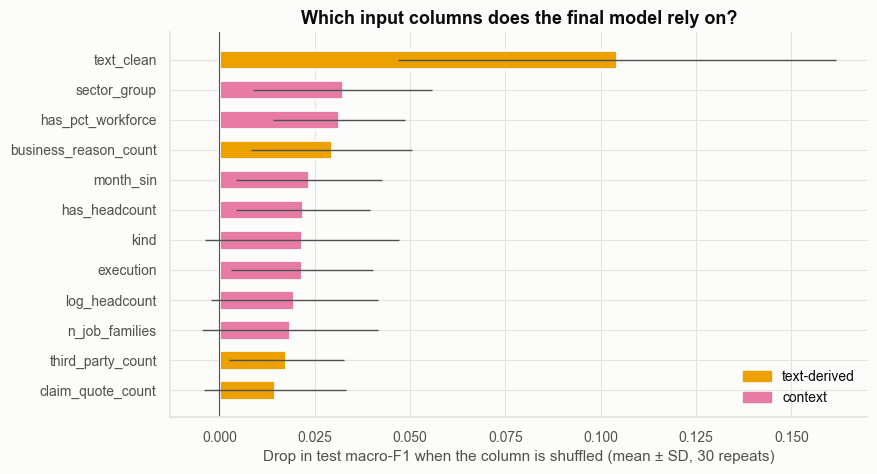

,column,importance,std
0,text_clean,0.1043,0.0574
1,sector_group,0.0323,0.0235
2,has_pct_workforce,0.0314,0.0173
3,business_reason_count,0.0294,0.0211
4,month_sin,0.0235,0.0192
5,has_headcount,0.0218,0.0175
6,kind,0.0216,0.0253
7,execution,0.0216,0.0187
8,log_headcount,0.0196,0.0218
9,n_job_families,0.0184,0.0231


In [29]:
input_cols = EXPERIMENTS[CONFIG_KEYS[FINAL_CONFIG]]["columns"]
perm = permutation_importance(final_estimator, test_df[input_cols], y_test, scoring="f1_macro",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
perm_tbl = (pd.DataFrame({"column": input_cols, "importance": perm.importances_mean, "std": perm.importances_std})
            .sort_values("importance", ascending=False).reset_index(drop=True))
perm_tbl.to_csv(RESULTS_DIR / "permutation_importance.csv", index=False)

top = perm_tbl.head(12).iloc[::-1]
text_side = set(BLOCKS["text_numeric"] + BLOCKS["text_binary"] + [BLOCKS["text"]])
fig, ax = plt.subplots(figsize=(9, 5))
cols_ = [CONFIG_COLORS["Text only"] if c in text_side else CONFIG_COLORS["Context only"] for c in top.column]
ax.barh(top.column, top.importance, xerr=top["std"], color=cols_, edgecolor=SURFACE, linewidth=2, height=0.65,
        error_kw={"ecolor": TEXT2, "elinewidth": 1})
ax.axvline(0, color=TEXT2, linewidth=0.8)
ax.set_xlabel("Drop in test macro-F1 when the column is shuffled (mean ± SD, 30 repeats)")
ax.set_title("Which input columns does the final model rely on?")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CONFIG_COLORS["Text only"], label="text-derived"),
                   Patch(color=CONFIG_COLORS["Context only"], label="context")], loc="lower right")
savefig(fig, "fig29_permutation_importance")
display(perm_tbl.head(12).round(4))

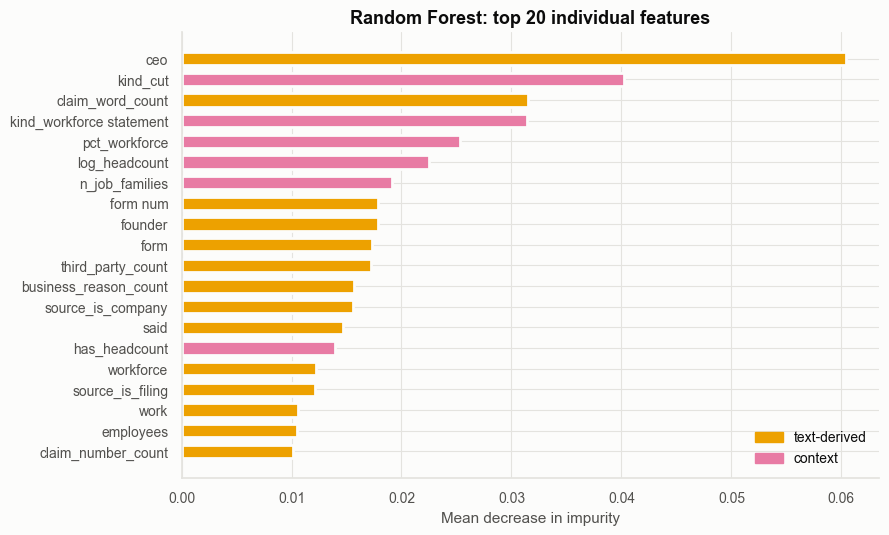

Share of total RF importance per feature block:
tfidf       0.612
ctx_cat     0.138
ctx_num     0.090
text_num    0.089
ctx_bin     0.044
text_bin    0.028


In [30]:
pre_fitted = final_estimator.named_steps["pre"]
feat_names = pre_fitted.get_feature_names_out()
rf_imp = (pd.Series(final_estimator.named_steps["clf"].feature_importances_, index=feat_names)
          .sort_values(ascending=False))
rf_top = rf_imp.head(20).rename(lambda s: s.split("__", 1)[1] if "__" in s else s)
fig, ax = plt.subplots(figsize=(9, 5.8))
is_text = [n.startswith(("tfidf", "text_")) for n in rf_imp.head(20).index]
ax.barh(rf_top.index[::-1], rf_top.values[::-1],
        color=[CONFIG_COLORS["Text only"] if t else CONFIG_COLORS["Context only"] for t in is_text[::-1]],
        edgecolor=SURFACE, linewidth=2, height=0.65)
ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Random Forest: top 20 individual features")
ax.legend(handles=[Patch(color=CONFIG_COLORS["Text only"], label="text-derived"),
                   Patch(color=CONFIG_COLORS["Context only"], label="context")], loc="lower right")
savefig(fig, "fig30_rf_feature_importance")

block_share = rf_imp.groupby(lambda s: s.split("__")[0]).sum().sort_values(ascending=False)
print("Share of total RF importance per feature block:")
print(block_share.round(3).to_string())

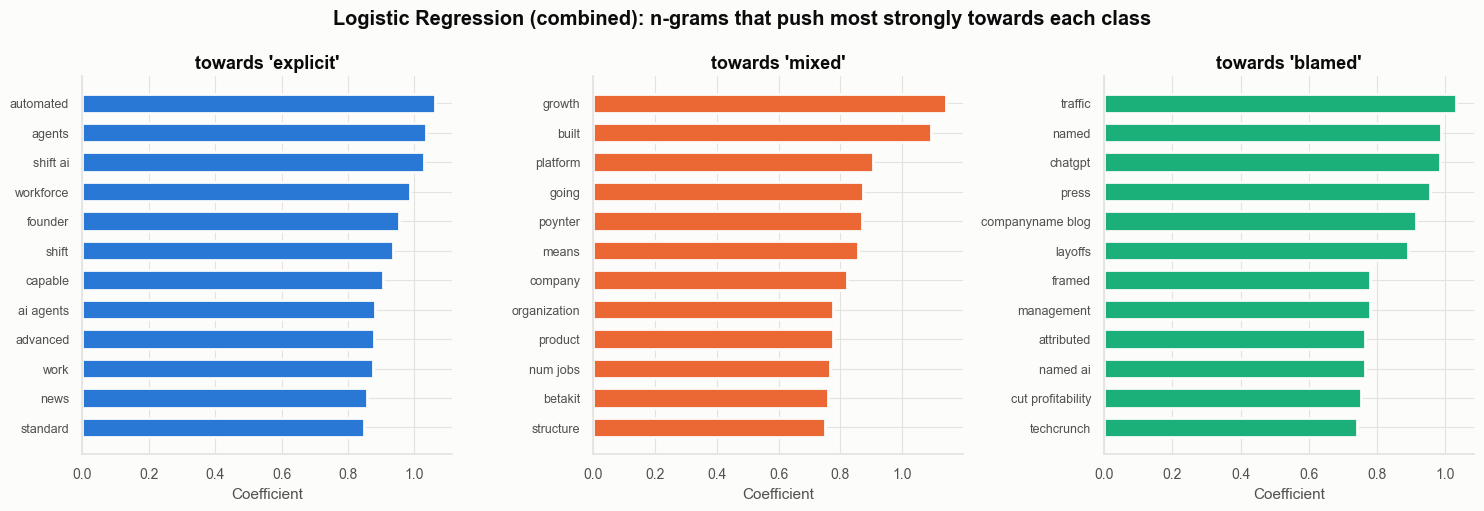

,top positive features
class,
explicit,"automated, agents, shift ai, workforce, founder, shift, capable, ai agents, advanced, work, news, standard"
mixed,"growth, built, platform, going, poynter, means, company, organization, product, num jobs, betakit, structure"
blamed,"traffic, named, chatgpt, press, companyname blog, layoffs, framed, management, attributed, named ai, cut p..."


,top positive non-text features
class,
explicit,"kind_workforce statement, country_primary_france, country_primary_spain, sector_group_fintech_crypto, jf_c..."
mixed,"execution_partial, country_primary_norway, claim_word_count, country_primary_australia, jf_sales_and_marke..."
blamed,"jf_content_moderation, kind_cut, country_primary_ireland, country_primary_united kingdom, third_party_coun..."


In [31]:
lr_est = searches[("Logistic Regression", "Combined")].best_estimator_
full_names = lr_est.named_steps["pre"].get_feature_names_out()
lr_names = np.array([n.split("__", 1)[1] for n in full_names])
coef_all = pd.DataFrame(lr_est.named_steps["clf"].coef_, index=lr_est.named_steps["clf"].classes_, columns=lr_names)
is_ngram = np.array([n.startswith("tfidf__") for n in full_names])
coef = coef_all.loc[:, is_ngram]                     # n-grams only for the plot (the text cues)

TOP_N = 12
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
coef_rows = []
for ax, cls in zip(axes, CLASSES):
    top_terms = coef.loc[cls].sort_values(ascending=False).head(TOP_N)
    coef_rows.append({"class": cls, "top positive features": ", ".join(top_terms.index)})
    ax.barh(top_terms.index[::-1], top_terms.values[::-1], color=CLASS_COLORS[cls], edgecolor=SURFACE,
            linewidth=2, height=0.65)
    ax.set_title(f"towards '{cls}'")
    ax.set_xlabel("Coefficient")
    ax.tick_params(axis="y", labelsize=9)
fig.suptitle("Logistic Regression (combined): n-grams that push most strongly towards each class", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig31_lr_coefficients")
display(pd.DataFrame(coef_rows).set_index("class"))
ctx_rows = [{"class": c, "top positive non-text features": ", ".join(
    coef_all.loc[c, ~is_ngram].sort_values(ascending=False).head(8).index)} for c in CLASSES]
display(pd.DataFrame(ctx_rows).set_index("class"))

**Answer to RQ1.**
- **The claim text is the single most informative input.** Shuffling `text_clean` costs ≈ 0.10 test macro-F1, about three times more than any other column, and the TF-IDF block holds ≈ 61 % of the forest's total importance.
- **What the text cues are** (Logistic Regression n-grams): *explicit* is pushed by first-person AI-strategy wording such as "automated", "agents", "shift ai", "founder", "capable"; *blamed* by reporting/attribution wording such as "press", "named", "framed", "chatgpt", "layoffs"; *mixed* by business-plan vocabulary such as "growth", "platform", "built". This matches the label definitions and the χ² analysis of Part 1. (Some cues are names of outlets, e.g. "poynter", a reminder that the model also learns the register's sources.)
- The **engineered text statistics** help too: `business_reason_count` and `third_party_count` are among the more important columns, as Part 1's EDA predicted.
- **Context matters as a group, not one by one.** No single context column comes close to the text, but together they matter: in the permutation test `sector_group`, whether a % of workforce / headcount is reported (`has_pct_workforce`, `has_headcount`), month, `kind` and `execution` each cost 0.02–0.03, and the context blocks hold ≈ 27 % of the forest's importance. The strongest single context signal in the linear model is `kind = workforce statement` → *explicit* (an employer talking about AI and headcount in general is usually explicit about AI). Missing size information is itself informative because, as Part 1 found, it is structurally linked to how events were reported.
- Permutation importances on a 75-event test set are noisy (see the error bars), and single country coefficients in the linear model rest on very few events, so the ranking of the smaller features should be read as indicative only.

## 14. Error analysis
We list the final model's test-set errors, look at which class pairs are confused, and check whether errors concentrate in particular kinds of events.

In [32]:
proba_test = final_estimator.predict_proba(test_df)
cls_order = list(final_estimator.classes_)
err = test_df.assign(predicted=final_pred,
                     confidence=proba_test.max(axis=1),
                     p_true=[proba_test[i, cls_order.index(t)] for i, t in enumerate(y_test)])
errors = err[err[TARGET] != err.predicted]

pair_counts = (errors.groupby([TARGET, "predicted"]).size().rename("errors").reset_index()
               .sort_values("errors", ascending=False))
print(f"Test errors: {len(errors)} of {len(err)} ({len(errors) / len(err):.0%})")
display(pair_counts.set_index([TARGET, "predicted"]))

def snippet(s, n=170):
    return s if len(s) <= n else s[:n].rsplit(" ", 1)[0] + " ..."

show_err = errors.sort_values("confidence", ascending=False)[
    ["company", "date", TARGET, "predicted", "confidence", "third_party_count", "ai_term_count", "claim"]].copy()
show_err["date"] = show_err["date"].dt.date
show_err["claim"] = show_err["claim"].map(snippet)
display(show_err.head(12))

Test errors: 26 of 75 (35%)


errors
attribution predicted        
mixed       explicit        8
blamed      mixed           7
mixed       blamed          7
explicit    blamed          3
            mixed           1

,company,date,attribution,predicted,confidence,third_party_count,ai_term_count,claim
57,IBM,2025-05-05,mixed,explicit,0.685226,0,2,"CEO Arvind Krishna told the Wall Street Journal that IBM replaced ""a couple hundred"" HR workers with AI ag..."
74,IBM,2023-05-01,mixed,explicit,0.664658,0,2,"CEO Arvind Krishna said he could 'easily see 30 per cent' of IBM's roughly 26,000 non-customer-facing back..."
7,Reach plc,2026-09-16,mixed,blamed,0.537448,0,1,"The Journal, reporting Reach's announcement of 'redundancies in around 220 full-time equivalent jobs in ed..."
17,Uber,2026-07-22,mixed,blamed,0.518703,2,3,"Uber cut about 10% of its Community Operations (customer-support) organization, reported by Bloomberg on J..."
1,Bank of America,2026-10-14,mixed,explicit,0.514072,0,6,"CFO Alastair Borthwick, prepared remarks, Q3 2026 earnings call (October 14, 2026): ""We also invested in t..."
51,Commonwealth Bank,2025-08-21,explicit,blamed,0.491401,0,1,"CBA said in July 2025 it would cut 45 call-center roles after an AI voice bot took over customer queries, ..."
41,McKinsey & Company,2025-11-26,mixed,blamed,0.486329,0,1,"McKinsey spokesperson, emailed statement: ""We are continually working to make our professional support fun..."
36,Telstra,2026-02-10,mixed,blamed,0.481445,0,3,A spokesperson for Telstra's data and AI joint venture with Accenture told the ABC the changes 'would see ...
68,IBM,2024-03-13,blamed,mixed,0.479184,0,3,"Le Monde Informatique (March 18, 2024): ""IBM France a décidé d'engager un plan social justifié par les gai..."
39,IBM,2026-01-27,blamed,mixed,0.477759,3,4,"Bruzz (27 January 2026), reporting the joint press release of the BBTK, ACV Puls, CNE and ACLVB unions: ""D..."


In [33]:
by_group = []
for col, label in [("kind", "event kind"), ("execution", "execution"), ("region", "region")]:
    g = err.groupby(col).apply(lambda d: pd.Series({"events": len(d), "error rate": (d[TARGET] != d.predicted).mean()}),
                               include_groups=False)
    g.index = [f"{label}: {i}" for i in g.index]
    by_group.append(g)
by_group = pd.concat(by_group)
by_group["events"] = by_group["events"].astype(int)
display(by_group[by_group.events >= 3].style.format({"error rate": "{:.0%}"}))

conf_ok = err.groupby(err[TARGET] == err.predicted)["confidence"].mean()
print(f"Mean confidence when correct: {conf_ok.get(True, np.nan):.2f}; when wrong: {conf_ok.get(False, np.nan):.2f}")
print(f"Mean confidence when the model is very sure (top 25%): accuracy = "
      f"{(err[err.confidence >= err.confidence.quantile(0.75)].pipe(lambda d: (d[TARGET] == d.predicted).mean())):.0%}")

,events,error rate
event kind: cut,70,33%
event kind: workforce statement,5,60%
execution: announced,25,32%
execution: executed,46,37%
region: asia_pacific,8,50%
region: europe,14,36%
region: middle_east,7,14%
region: north_america,44,34%


Mean confidence when correct: 0.56; when wrong: 0.47
Mean confidence when the model is very sure (top 25%): accuracy = 89%


**What we see.**
- **22 of the 26 errors involve the *mixed* class**: *mixed → explicit* (8) and *blamed ↔ mixed* (14 in total). These are exactly the boundaries the register itself has to judge, so they are genuinely ambiguous cases rather than random noise.
- **mixed → explicit** is the largest single error type, and the most confident errors show why: e.g. IBM's CEO saying IBM replaced "a couple hundred" HR workers with AI agents reads like an *explicit* claim, but the register labels the event *mixed* because other reasons were also given. A model that only sees the summary text cannot know about those other reasons.
- **mixed ↔ blamed** errors are mostly third-party reports (newspapers, unions, LinkedIn posts) about cuts where the employer's own statement was short or indirect.
- **explicit → blamed** (3 of the 7 explicit test events) is the most worrying confusion because it jumps over *mixed*. These are short claims where the AI link is told in reported speech (e.g. "CBA said ... after an AI voice bot took over"), which looks like third-party wording.
- **Minority-class effect:** with class weighting the model does predict *explicit* (recall 3/7), but its precision is low (several *mixed* events are pulled into *explicit*), so explicit F1 (0.33) stays the weakest score. *Workforce statements* (only 5 test events) have the highest error rate. More *explicit* examples are the single biggest need.
- **Confidence is informative:** the model's confidence is clearly higher on correct predictions than on errors, and the most confident quarter of predictions is much more accurate than average. This supports showing the confidence in the demo, with a note that low-confidence predictions deserve manual review.
- **Limitation of automated classification:** many errors are short claims that quote AI-flavoured language while the register's judgement depends on details outside the text (e.g. what a later filing said). A text classifier cannot know what the employer *did not* say elsewhere.

## 15. Final machine learning pipeline
The complete pipeline is a single scikit-learn object:

```
raw event fields ──► src/attribution_features.engineer_features()   (Part 1 cleaning, masking, feature engineering)
                 ──► ColumnTransformer  (TF-IDF + χ² selection | scaled text statistics | one-hot context | scaled numeric | binary flags)
                 ──► RandomForestClassifier (tuned)   [+ sigmoid calibration if selected in 12.3]
                 ──► predicted attribution + class confidences
```

**Training data for the deployed model.** All evaluation above used models trained on the 245 training events only. For the demo we re-fit the *same* pipeline with the *same* hyperparameters on **all 320 events**, which is standard practice once model selection and evaluation are finished (more data, and the learning curve showed that more data helps). The reported performance remains the honest test-set estimate from Section 10.

In [34]:
final_pipeline = calibrated if USE_CALIBRATION else clone(final_estimator)
final_pipeline = clone(final_pipeline).fit(df, df[TARGET])

model_path = MODEL_DIR / "final_pipeline.joblib"
joblib.dump(final_pipeline, model_path)

metadata = {
    "model": FINAL_MODEL, "feature_configuration": FINAL_CONFIG, "calibrated": bool(USE_CALIBRATION),
    "hyperparameters": {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                        for k, v in final_search.best_params_.items()},
    "input_columns": input_cols, "classes": CLASSES, "trained_on_events": int(len(df)),
    "selection": "highest mean grouped 4-fold CV macro-F1 on the 245 training events",
    "cv_macro_f1": round(float(final_search.best_score_), 4),
    "test_metrics_train_only_model": {k: round(float(v), 4) for k, v in final_scores.items()},
    "test_macro_f1_95ci": [round(float(x), 4) for x in bootstrap_ci(y_test, final_pred, macro)],
    "majority_baseline_test_macro_f1": round(float(macro(y_test, majority_pred)), 4),
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
                 "numpy": np.__version__},
    "disclaimer": "Predicts the register's attribution category from how an event was reported. "
                  "It is not evidence that AI caused any job losses.",
}
with open(MODEL_DIR / "model_metadata.json", "w", encoding="utf-8") as fh:
    json.dump(metadata, fh, indent=2)
print(f"Saved {model_path} ({model_path.stat().st_size / 1e6:.1f} MB) and models/model_metadata.json")
print(json.dumps({k: metadata[k] for k in ["model", "feature_configuration", "calibrated", "cv_macro_f1",
                                           "test_macro_f1_95ci"]}, indent=2))

Saved models\final_pipeline.joblib (2.6 MB) and models/model_metadata.json
{
  "model": "Random Forest",
  "feature_configuration": "Combined",
  "calibrated": false,
  "cv_macro_f1": 0.6645,
  "test_macro_f1_95ci": [
    0.4393,
    0.6965
  ]
}


### 15.1 End-to-end check: from raw text to a prediction
We reload the saved pipeline from disk and classify three **made-up** event descriptions (not from the dataset), passing them through exactly the same feature module the demo uses. This proves the whole chain works outside the notebook's memory.

In [35]:
loaded = joblib.load(MODEL_DIR / "final_pipeline.joblib")
new_events = pd.DataFrame([
    {"company": "Example Software Inc", "date": "2026-11-10", "sector": "Software / SaaS", "country": "United States",
     "kind": "cut", "execution": "announced", "headcount": 400, "pct_of_workforce": "about 8% of staff",
     "job_families": "Customer service and support",
     "claim": "In a blog post the CEO wrote that AI agents now handle most customer support tickets, "
              "so the company is eliminating 400 support roles: \"AI lets us do this work with far fewer people.\"",
     "source_title": "Example Software blog: Building an AI-first company"},
    {"company": "Example Bank", "date": "2026-09-02", "sector": "Banking", "country": "United Kingdom",
     "kind": "cut", "execution": "executed", "headcount": 1200, "pct_of_workforce": "",
     "job_families": "Operations and back office; Corporate functions",
     "claim": "The bank said the cuts are part of a cost-reduction and restructuring programme to improve efficiency, "
              "citing simplification, automation and the use of AI among the drivers.",
     "source_title": "Example Bank Q2 results announcement"},
    {"company": "Example Retail", "date": "2026-08-15", "sector": "Retail", "country": "Germany",
     "kind": "cut", "execution": "announced", "headcount": 300, "pct_of_workforce": "",
     "job_families": "",
     "claim": "According to the union, the job losses are linked to the rollout of automated systems; "
              "people familiar with the plan told reporters AI tools will take over the work.",
     "source_title": "Local newspaper report on retail job cuts"},
])
X_new = engineer_features(new_events)
proba_new = loaded.predict_proba(X_new)
out = pd.DataFrame(proba_new, columns=loaded.classes_)[CLASSES].round(2)
out.insert(0, "predicted", loaded.predict(X_new))
out.insert(0, "event", ["CEO blog: AI replaces support", "Bank results: cost + AI", "Union/press: AI blamed"])
display(out)

,event,predicted,explicit,mixed,blamed
0,CEO blog: AI replaces support,explicit,0.40,0.39,0.21
1,Bank results: cost + AI,mixed,0.26,0.41,0.34
2,Union/press: AI blamed,blamed,0.33,0.22,0.45


**Result.** The pipeline loads from disk and produces sensible predictions for new, hand-written events: an employer's own AI statement leans *explicit*, a results announcement listing AI among cost reasons leans *mixed*, and a union/press report leans *blamed*. These are illustrations, not an evaluation.

### 15.2 Streamlit demo
`app.py` (project root) wraps this pipeline in a small web interface: the user enters a claim, source title and optional metadata; the app runs `engineer_features` and the saved pipeline, then shows the predicted category, the class confidences and the disclaimer. Run it with:

```bash
streamlit run app.py
```

## 16. Conclusions, limitations and future work

In [36]:
summary = {
    "final model": f"{FINAL_MODEL} on {FINAL_CONFIG.lower()} features",
    "CV macro-F1 (train, grouped 4-fold)": f"{final_search.best_score_:.3f}",
    "test macro-F1 [95% CI]": "{:.3f} [{:.3f}, {:.3f}]".format(final_scores["macro_f1"], *bootstrap_ci(y_test, final_pred, macro)),
    "test balanced accuracy": f"{final_scores['balanced_accuracy']:.3f}",
    "test accuracy": f"{final_scores['accuracy']:.3f}",
    "majority reference (test macro-F1)": f"{macro(y_test, majority_pred):.3f}",
    "per-class test F1 (explicit / mixed / blamed)": " / ".join(f"{final_scores['f1_' + c]:.2f}" for c in CLASSES),
    "best text-only CV macro-F1": f"{cv_results[cv_results.config == 'Text only'].cv_macro_f1.max():.3f}",
    "best context-only CV macro-F1": f"{cv_results[cv_results.config == 'Context only'].cv_macro_f1.max():.3f}",
    "best combined CV macro-F1": f"{cv_results[cv_results.config == 'Combined'].cv_macro_f1.max():.3f}",
    "chronological hold-out macro-F1": f"{ch_scores['macro_f1']:.3f}",
    "without verdict phrases (test macro-F1)": f"{nv_scores['macro_f1']:.3f}",
    "figures saved in this notebook": len(FIGURES_SAVED),
    "total run time (min)": f"{(time.time() - NOTEBOOK_START) / 60:.1f}",
}
summary_tbl = pd.Series(summary, name="value").to_frame()
summary_tbl.to_csv(RESULTS_DIR / "final_summary.csv")
display(summary_tbl)
print("Figures:", FIGURES_SAVED)

,value
final model,Random Forest on combined features
"CV macro-F1 (train, grouped 4-fold)",0.665
test macro-F1 [95% CI],"0.570 [0.439, 0.696]"
test balanced accuracy,0.597
test accuracy,0.653
majority reference (test macro-F1),0.250
per-class test F1 (explicit / mixed / blamed),0.33 / 0.72 / 0.65
best text-only CV macro-F1,0.618
best context-only CV macro-F1,0.510
best combined CV macro-F1,0.665


Figures: ['fig19_split_composition.png', 'fig20_cv_macro_f1_heatmap.png', 'fig21_class_weighting.png', 'fig22_chi2_k_curve.png', 'fig23_learning_curve.png', 'fig24_confusion_matrix_final.png', 'fig25_cv_vs_test.png', 'fig26_rq2_feature_configs.png', 'fig27_robustness.png', 'fig28_calibration.png', 'fig29_permutation_importance.png', 'fig30_rf_feature_importance.png', 'fig31_lr_coefficients.png']


### Conclusions
1. **The attribution category can be predicted well above chance from how an event is reported.** The final Random Forest reaches test macro-F1 0.57 (95 % CI 0.44–0.70) on companies it has never seen, more than twice the majority reference (0.25); its CV macro-F1 is 0.665.
2. **RQ1:** the claim wording is the key evidence. Third-party reporting language signals *blamed*, business-plan vocabulary signals *mixed*, and first-person AI-strategy statements signal *explicit*. Context features are weak one by one but useful as a group (event kind, sector, whether size figures were reported).
3. **RQ2:** text ≫ context. Combining both improves CV macro-F1 for all five models (+0.02 to +0.05), but on a 75-event test set the gain is not statistically clear-cut.
4. **RQ3:** bagging (Random Forest) is the best approach in CV; boosting is not better than the traditional models on this small dataset, and Naive Bayes is a remarkably strong simple baseline.
5. The model does not rely on the register's verdict phrases, and it performs as well on the most recent events (chronological hold-out) as on the grouped test fold.

### Limitations
- **Small, imbalanced data:** 320 events, 39 *explicit*. All estimates carry wide uncertainty (see the bootstrap CIs and fold SDs); small differences between models are not meaningful.
- **Labels are one organisation's judgement** of what was said, not ground truth about causes; the model reproduces that judgement, including any inconsistencies.
- **Text is a summary written by the register**, so the model partly learns the register's writing style. Raw press releases or news articles may look different.
- **Temporal drift:** no decay was visible in this snapshot, but the recent period has only 3 *explicit* events and AI-layoff vocabulary changes quickly, so this needs re-checking as the register grows.
- **Probabilities are not calibrated:** calibration hurt classification on this small dataset, so the demo's confidence values are relative, not exact probabilities.

### Future work
- Re-train as the register grows (the learning curve is still rising), especially with more *explicit* events.
- Try sentence-embedding or small transformer models once there is more data; with 245 events they are likely to overfit.
- Ordinal modelling (explicit > mixed > blamed are ordered by attribution strength) could reduce the far-apart errors further.

---
**End of Part 2.** All results above are reproducible with *Kernel → Restart & Run All* (see README).